<a href="https://colab.research.google.com/github/mdelgiudicechaves-art/Trabalho-SSD---MVP---Final/blob/main/Gerador_MVP_Trabalho_PSP_8_v2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# MVP — Clusterização de clientes e estratégia comercial · **Gerador dos 4 notebooks**
**Universidade de Brasília - Prof. André Luiz Marques Serrano**
Base: *Customer Personality Analysis* (Kaggle)

Este notebook do Colab **prepara o MVP**: coleta e documenta os dados, analisa a qualidade (incluindo **duplicatas re-chaveadas**), ensaia Silver e Gold localmente, monta o catálogo de dados e o diagrama, **gera os 4 notebooks Databricks** (Bronze → Silver → Gold → Análise) em **`.py` (formato source) e `.ipynb`**, a definição do Job, o README, a LICENSE e o `.zip` do repositório.

O **notebook unificado** (`MVP_Unificado.ipynb`) usa exatamente o mesmo núcleo de código e traz os resultados da análise embutidos (para o GitHub).


### Premissas deste trabalho (declaradas)
- **Nenhum resultado é inventado:** toda saída numérica vem da execução.
- Plataforma: Databricks **Free Edition** (serverless; Unity Catalog, catálogo `workspace`).
- Volume pequeno (2.240 linhas): Silver e clusterização em pandas/scikit-learn; Bronze, Delta, esquema estrela e visões em Spark/SQL.
- K-Means sobre RFM + perfil; `k` = maior *silhouette* com `k ≥ 3` (k=2 só separa alto/baixo valor, pouco acionável); estabilidade por sementes e bootstrap.
- `Z_CostContact` e `Z_Revenue` são **premissa** de custo por contato e receita por aceite (a base não documenta o significado).
- **R11 (novo):** registros idênticos em todos os atributos exceto o `ID` são removidos da Silver (a Bronze os preserva). `REMOVER_DUPLICATAS = False` reproduz o comportamento da versão anterior.


## 1. Mapa do checklist de entrega (seção 8 do PDF) e da rubrica (seção 7)

| Item do checklist / critério (pontos) | Onde está | Evidência no repositório |
|---|---|---|
| Objetivo e perguntas documentados e íntegros (**Objetivo 1,0**) | Seção 2 deste notebook; README | `README.md` |
| Origem, licença e data de coleta registradas (**Coleta 0,5**) | Seções 2 e 4 | `catalogo/metadados_coleta.json` |
| Dados persistidos na nuvem (**Coleta/Carga**) | Seção 10; notebooks 01–03 | prints das tabelas Delta em `evidencias/` |
| Modelo de dados descrito + Catálogo com domínios e linhagem (**Modelagem 2,0**) | Seções 7 e 8 | `catalogo/catalogo_dados.csv/.md`, `catalogo/diagrama_estrela.*` |
| Transformação e carga documentadas, regras explícitas (**Carga 1,0**) | Seção 6; notebooks 01–03; job | `catalogo/regras_transformacao.csv`, `notebooks/` |
| Análise de qualidade de todos os atributos (**Análise 1,0**) | Seção 5 | `evidencias/qualidade_*.png`, tabela no README |
| Notebook unificado com resultados embutidos (**Capricho**) | `MVP_Unificado.ipynb` | saídas do notebook + `resultados_resumo.json` |
| Cada pergunta com resposta, evidência e discussão (**Análise 1,0 + 1,0**) | Notebook Databricks `04_analise_p1_p5` | prints dos gráficos em `evidencias/` |
| Discussão geral conectando respostas à solução (**Análise**) | `04_analise_p1_p5` (última seção) | README |
| Autoavaliação presente (**Autoavaliação 0,5**) | Seção 12 | README |
| Evidências legíveis e referenciadas no texto (**Capricho 2,0**) | Seção 14 | `evidencias/` |
| Repositório público e conferido em janela anônima (**Capricho**) | Seção 13 | link na postagem do fórum |
| Ética, licença e LGPD (seção 4 do PDF) | Seção 11 | README |

## 2. Objetivo, perguntas de negócio e origem dos dados

**Problema.** A empresa trata a base de clientes de forma homogênea.
**Hipótese.** Existem segmentos naturais com valor, comportamento e resposta a campanhas diferentes; priorizar o orçamento comercial por segmento aumenta o retorno.

**Perguntas de negócio** (mantidas integralmente, mesmo que alguma não seja respondida):

- **P1.** Quantos segmentos naturais de clientes existem (K-Means sobre RFM + perfil demográfico) e qual o perfil de cada um em renda, composição familiar, gasto e frequência?
- **P2.** Qual a contribuição de cada segmento para a receita total e o gasto médio por cliente? Que fração dos clientes concentra 80% do gasto (Pareto)?
- **P3.** Como os segmentos diferem em mix de categorias (vinhos, carnes, peixes, frutas, doces, ouro) e em canal (loja, web, catálogo)? Qual o papel das visitas web e das compras com desconto?
- **P4.** Qual a taxa de aceitação das campanhas (1 a 5 e a última) por segmento? Sob a premissa declarada custo por contato = `Z_CostContact` e receita por aceite = `Z_Revenue`, qual segmento tem melhor retorno estimado? *(O significado de `Z_*` é uma premissa, pois a base não o documenta.)*
- **P5.** Quais clientes têm alto gasto histórico e recência alta (risco de inatividade) e que ação de retenção/reativação faz sentido para eles?

**Entrega final de negócio:** playbook comercial com uma ação recomendada por segmento (oferta, canal, prioridade).

**Origem dos dados.** Kaggle — *Customer Personality Analysis* (`imakash3011/customer-personality-analysis`), arquivo `marketing_campaign.csv`, separado por TAB, 2.240 linhas × 29 colunas.
**Licença.** CC0 (domínio público) conforme indicado na página do dataset — *confirme na página no dia da entrega* (`# TODO` na seção 3).
**Data de coleta, volume e formato:** registrados automaticamente na seção 4.

## 3. Configuração (única célula de parâmetros)

In [3]:
# ============================ CONFIGURAÇÃO ÚNICA ============================
import os, sys, json, hashlib, datetime as dt, warnings
from pathlib import Path
warnings.filterwarnings("ignore")

# --- Pastas -----------------------------------------------------------------
BASE = (Path("/content/mvp_unb") if Path("/content").exists() else Path("mvp_unb")).resolve()
for sub in ["dados", "catalogo", "evidencias", "scripts", "notebooks", "databricks", "databricks/_templates"]:
    (BASE / sub).mkdir(parents=True, exist_ok=True)
os.chdir(BASE)

# --- Dados ------------------------------------------------------------------
KAGGLE_DATASET = "imakash3011/customer-personality-analysis"
CSV_NAME = "marketing_campaign.csv"
CSV_LOCAL_PATH = os.environ.get("MVP_CSV_LOCAL", "")   # opcional: caminho de um CSV já existente (pula o download)
LICENCA_DADOS = "CC0: Public Domain"   # TODO: confirme na página do dataset e atualize se for diferente
DATA_CONFERENCIA_LICENCA = "02/11/2026"  # TODO: preencha a data em que conferiu a licença

# --- Databricks (Unity Catalog; Free Edition usa o catálogo "workspace") -----
CATALOG = "workspace"
SCHEMA = "mvp_marketing"
VOLUME = "raw"
USAR_SDK = False   # True = tenta enviar CSV/notebooks e criar o job via Databricks SDK (seção 10); False = passo manual

# --- Parâmetros do modelo e das regras --------------------------------------
SEED = 42
K_MAX = 8                 # testa k de 2 até K_MAX
K_MIN_ESCOLHA = 3         # k escolhido = maior silhouette com k >= K_MIN_ESCOLHA
PCT_RISCO_GASTO = 0.75    # P5: alto gasto = acima deste percentil
PCT_RISCO_RECENCIA = 0.75 # P5: recência alta (dias sem comprar) = acima deste percentil
N_CONTATOS_POR_CLIENTE = 6   # premissa P4: cada cliente recebeu as 6 campanhas (1 a 5 + última)
REMOVER_DUPLICATAS = True    # R11: remove registros idênticos exceto o ID (a Bronze preserva todos)

# --- Autor (usado no README/LICENSE) ----------------------------------------
NOME_ALUNO = "Marina del Giudice Chaves"   # TODO: confira o nome
MATRICULA = "231025360"                    # TODO: confira a matrícula
print("Pasta de trabalho:", BASE)

Pasta de trabalho: /content/mvp_unb


In [4]:
import importlib, subprocess
def _garantir(pacote, modulo=None):
    try:
        importlib.import_module(modulo or pacote)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--root-user-action=ignore", pacote], check=True,
                       stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
_garantir("kagglehub"); _garantir("databricks-sdk", "databricks.sdk")


### 3.1 Núcleo de lógica (arquivos em `scripts/`)
As três células abaixo gravam os módulos reutilizados no Colab **e inseridos nos notebooks Databricks**, para que o ensaio local e a execução na nuvem façam exatamente o mesmo:
`mvp_core.py` (qualidade, Silver, K-Means, Gold, catálogo) · `mvp_analise.py` (estatística, gráficos e discussões geradas dos números) · `mvp_views.py` (visões SQL).


In [5]:
%%writefile scripts/mvp_core.py
# ============================================================
# NÚCLEO DE LÓGICA DO MVP — parte 1: bases, mapeamentos e nomes
# Funções puras em pandas/scikit-learn (2.240 linhas: pandas basta e é testável).
# ============================================================
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (silhouette_score, adjusted_rand_score,
                             davies_bouldin_score, calinski_harabasz_score)

RENOMEAR = {
    "ID": "cliente_id", "Year_Birth": "ano_nascimento", "Education": "educacao_original",
    "Marital_Status": "estado_civil_original", "Income": "renda",
    "Kidhome": "filhos_criancas", "Teenhome": "filhos_adolescentes",
    "Dt_Customer": "data_cadastro", "Recency": "recencia_dias",
    "MntWines": "gasto_vinhos", "MntFruits": "gasto_frutas", "MntMeatProducts": "gasto_carnes",
    "MntFishProducts": "gasto_peixes", "MntSweetProducts": "gasto_doces", "MntGoldProds": "gasto_ouro",
    "NumDealsPurchases": "compras_desconto", "NumWebPurchases": "compras_web",
    "NumCatalogPurchases": "compras_catalogo", "NumStorePurchases": "compras_loja",
    "NumWebVisitsMonth": "visitas_web_mes",
    "AcceptedCmp1": "campanha_1", "AcceptedCmp2": "campanha_2", "AcceptedCmp3": "campanha_3",
    "AcceptedCmp4": "campanha_4", "AcceptedCmp5": "campanha_5", "Response": "campanha_ultima",
    "Complain": "reclamacao_2anos",
}
CATEGORIAS = ["vinhos", "carnes", "peixes", "frutas", "doces", "ouro"]
COLS_GASTO = [f"gasto_{c}" for c in CATEGORIAS]
COLS_CAMPANHA = ["campanha_1", "campanha_2", "campanha_3", "campanha_4", "campanha_5", "campanha_ultima"]
COLS_ORIGINAIS_GASTO = ["MntWines", "MntFruits", "MntMeatProducts", "MntFishProducts", "MntSweetProducts", "MntGoldProds"]
COLS_ORIGINAIS_CANAL = ["NumWebPurchases", "NumCatalogPurchases", "NumStorePurchases"]
COLS_ORIGINAIS_BINARIAS = ["AcceptedCmp1", "AcceptedCmp2", "AcceptedCmp3", "AcceptedCmp4",
                           "AcceptedCmp5", "Complain", "Response"]
MAP_EDUCACAO = {  # original -> (padronizada, nível ordinal)
    "Basic": ("Básico", 1), "Graduation": ("Graduação", 2),
    "2n Cycle": ("Mestrado", 3),  # premissa: 2n Cycle = 2º ciclo (Bologna) ~ mestrado
    "Master": ("Mestrado", 3), "PhD": ("Doutorado", 4),
}
MAP_ESTADO_CIVIL = {  # original -> (padronizado, grupo)
    "Married": ("Casado(a)", "Com parceiro(a)"), "Together": ("União estável", "Com parceiro(a)"),
    "Single": ("Solteiro(a)", "Sem parceiro(a)"), "Alone": ("Solteiro(a)", "Sem parceiro(a)"),
    "Divorced": ("Divorciado(a)", "Sem parceiro(a)"), "Widow": ("Viúvo(a)", "Sem parceiro(a)"),
    "Absurd": ("Não informado", "Não informado"), "YOLO": ("Não informado", "Não informado"),
}
FEATURES_CLUSTER = ["recencia_dias", "compras_total", "gasto_total_log", "renda", "idade", "n_filhos"]


def _num(df, cols):
    for c in cols:
        df[c] = pd.to_numeric(df[c], errors="raise")
    return df


def tipar_bronze(bronze):
    """Bronze (tudo texto) -> DataFrame tipado, sem as colunas de metadados de ingestão."""
    df = bronze[[c for c in bronze.columns if not c.startswith("_")]].copy()
    return _num(df, [c for c in df.columns if c not in ("Education", "Marital_Status", "Dt_Customer")])


# ---------- QUALIDADE DE DADOS (sobre o dado bruto) -----------------------------
def perfil_atributos(df):
    """Uma linha por atributo: tipo, nulos, únicos, mín/máx, outliers (IQR 1,5) e observações."""
    linhas = []
    for c in df.columns:
        s = df[c]
        num = pd.api.types.is_numeric_dtype(s)
        obs = []
        if s.nunique(dropna=False) == 1:
            obs.append("constante")
        out = np.nan
        if num and s.nunique() > 2:
            q1, q3 = s.quantile([.25, .75])
            iqr = q3 - q1
            out = int(((s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)).sum())
        linhas.append({"atributo": c, "tipo": str(s.dtype), "nulos": int(s.isna().sum()),
                       "% nulos": round(100 * s.isna().mean(), 2), "únicos": int(s.nunique()),
                       "mín": s.min() if num else "", "máx": s.max() if num else "",
                       "outliers_IQR": out, "obs": ", ".join(obs)})
    return pd.DataFrame(linhas)


def duplicatas_sem_id(raw):
    """Registros idênticos em TODOS os atributos, exceto o ID (re-chaveados).
    Devolve DataFrame com (cliente_id_removido, cliente_id_mantido, grupo); mantém o menor ID de cada grupo."""
    cols = [c for c in raw.columns if c != "ID" and not c.startswith("_")]
    d = raw.sort_values("ID").reset_index(drop=True)
    grupo = d.groupby(cols, dropna=False, sort=False).ngroup()
    d = d.assign(_grupo=grupo)
    mantido = d.groupby("_grupo")["ID"].transform("min")
    extra = d[d["ID"] != mantido]
    return pd.DataFrame({"cliente_id_removido": extra["ID"].astype(int).values,
                         "cliente_id_mantido": mantido[extra.index].astype(int).values,
                         "grupo": extra["_grupo"].values}).reset_index(drop=True)


def testes_qualidade(raw):
    """Testes por dimensão de qualidade (completude, unicidade, consistência, conformidade, acurácia, atualidade)."""
    datas = pd.to_datetime(raw["Dt_Customer"], format="%d-%m-%Y", errors="coerce")
    compras = raw[COLS_ORIGINAIS_CANAL].sum(axis=1)
    idade_ref = datas.max().year - raw["Year_Birth"]
    q1, q3 = raw["Income"].quantile([.25, .75])
    n_dup = len(duplicatas_sem_id(raw))
    anos_defasagem = int(pd.Timestamp.today().year - datas.max().year)
    num_cols = [c for c in raw.columns if c not in ("Education", "Marital_Status", "Dt_Customer")]
    t = [
        ("Completude", "Income", "valores nulos", int(raw["Income"].isna().sum()), "Imputar pela mediana do nível de educação (R3)"),
        ("Completude", "demais colunas", "nulos fora de Income", int(raw.drop(columns="Income").isna().sum().sum()), "Nenhuma ação"),
        ("Unicidade", "linha inteira", "linhas duplicadas (com ID)", int(raw.duplicated().sum()), "Nenhuma ação"),
        ("Unicidade", "ID", "IDs duplicados", int(raw["ID"].duplicated().sum()), "Nenhuma ação"),
        ("Unicidade", "todos os atributos exceto ID", "registros repetidos com outro ID (duplicatas re-chaveadas)", n_dup,
         "Remover da Silver mantendo o menor ID; Bronze preserva tudo (R11)"),
        ("Consistência", "NumDealsPurchases vs canais", "compras com desconto > compras totais", int((raw["NumDealsPurchases"] > compras).sum()), "Manter e limitar % a 1 (R9)"),
        ("Consistência", "compras", "clientes com 0 compras mas gasto > 0", int(((compras == 0) & (raw[COLS_ORIGINAIS_GASTO].sum(axis=1) > 0)).sum()), "Manter; ticket/shares = 0 (R10)"),
        ("Conformidade", "Dt_Customer", "datas fora do formato dd-mm-aaaa", int(datas.isna().sum()), "Conversão explícita (R2)"),
        ("Conformidade", "Marital_Status", "categorias fora do domínio esperado (Alone/Absurd/YOLO)", int(raw["Marital_Status"].isin(["Alone", "Absurd", "YOLO"]).sum()), "Recodificar (R6)"),
        ("Conformidade", "Education", "categoria '2n Cycle' (nomenclatura distinta)", int((raw["Education"] == "2n Cycle").sum()), "Padronizar como Mestrado, preservando original (R7)"),
        ("Conformidade", "binárias", "valores fora de {0,1}", int(sum((~raw[c].isin([0, 1])).sum() for c in COLS_ORIGINAIS_BINARIAS)), "Nenhuma ação"),
        ("Conformidade", "Kidhome, Teenhome", "valores fora de 0–2", int(sum((~raw[c].between(0, 2)).sum() for c in ["Kidhome", "Teenhome"])), "Nenhuma ação"),
        ("Conformidade", "Recency", "valores fora de 0–99 dias", int((~raw["Recency"].between(0, 99)).sum()), "Nenhuma ação"),
        ("Conformidade", "Mnt*, Num*", "valores negativos em gastos/compras", int(sum((raw[c] < 0).sum() for c in COLS_ORIGINAIS_GASTO + COLS_ORIGINAIS_CANAL + ["NumDealsPurchases", "NumWebVisitsMonth"])), "Nenhuma ação"),
        ("Conformidade", "Z_CostContact, Z_Revenue", "colunas constantes", int(sum(raw[c].nunique() == 1 for c in ["Z_CostContact", "Z_Revenue"])), "Descartar; usar só como premissa de P4 (R1)"),
        ("Acurácia", "Year_Birth", "idade > 100 anos na data de referência", int((idade_ref > 100).sum()), "Imputar idade pela mediana (R5)"),
        ("Acurácia", "Income", "outlier extremo (> Q3+3·IQR)", int((raw["Income"] > q3 + 3 * (q3 - q1)).sum()), "Tratar como erro e imputar (R4)"),
        ("Atualidade", "Dt_Customer", f"cadastros de {datas.min().date()} a {datas.max().date()} (anos até hoje: {anos_defasagem})", anos_defasagem,
         "Dados defasados; registrar como limitação"),
    ]
    return pd.DataFrame(t, columns=["dimensão", "atributo", "teste", "ocorrências", "decisão"])


# ---------- SILVER: tipagem, qualidade e features ---------------------------------
def silver_transform(raw, remover_duplicatas=True):
    """Recebe o Bronze (pandas) e devolve (silver, log, constantes, duplicatas).
    log = DataFrame {regra, afetados, decisao} que documenta cada regra de negócio.
    duplicatas = DataFrame (cliente_id_removido, cliente_id_mantido) — vazio se remover_duplicatas=False."""
    log = []
    df = raw[[c for c in raw.columns if not c.startswith("_")]].copy()  # remove metadados de ingestão
    textos = ["Education", "Marital_Status", "Dt_Customer"]
    df = _num(df, [c for c in df.columns if c not in textos])

    # R11. Duplicatas re-chaveadas: todos os atributos iguais, exceto ID (executada primeiro)
    dup = duplicatas_sem_id(df)
    if remover_duplicatas and len(dup):
        df = df[~df["ID"].isin(dup["cliente_id_removido"])].copy()
        acao = ("Removidos da Silver (mantido o menor ID de cada grupo); a Bronze preserva todos os registros. "
                "Evita dupla contagem no K-Means, na receita e nas taxas de campanha")
    else:
        acao = "Mantidos (REMOVER_DUPLICATAS=False): apenas sinalizados em flag_duplicata"
    ids_dup = set(dup["cliente_id_removido"])
    df = df.sort_values("ID").reset_index(drop=True)
    df["flag_duplicata"] = df["ID"].isin(ids_dup)
    log.append({"regra": "R11 Duplicatas (atributos idênticos, ID diferente)", "afetados": int(len(dup)), "decisao": acao})

    # R1. Colunas constantes não carregam informação -> descartadas (valores guardados como premissa de P4)
    constantes = {c: df[c].iloc[0] for c in df.columns
                  if c != "flag_duplicata" and df[c].nunique(dropna=False) == 1}
    df = df.drop(columns=list(constantes))
    vals = [int(v) if float(v).is_integer() else float(v) for v in constantes.values()]
    log.append({"regra": "R1 Colunas constantes", "afetados": len(constantes),
                "decisao": f"Descartadas {list(constantes)} (valores {vals}); "
                           "mantidos só como premissa de custo/receita em P4"})

    df = df.rename(columns=RENOMEAR)

    # R2. Datas: Dt_Customer vem como dd-mm-aaaa
    df["data_cadastro"] = pd.to_datetime(df["data_cadastro"], format="%d-%m-%Y", errors="raise")
    data_ref = df["data_cadastro"].max()  # idade/tempo calculados na data de referência da base, não hoje
    log.append({"regra": "R2 Data de referência", "afetados": len(df),
                "decisao": f"data_ref = max(Dt_Customer) = {data_ref.date()}; idade e tempo de cliente calculados nela"})

    # R3/R4. Renda: nulos + outlier extremo (> Q3 + 3*IQR) -> NaN -> imputação pela mediana do nível de educação
    q1, q3 = df["renda"].quantile([.25, .75])
    limite = q3 + 3 * (q3 - q1)
    m_out = df["renda"] > limite
    m_nulo = df["renda"].isna()
    df["flag_renda_outlier"] = m_out
    df["flag_renda_imputada"] = m_out | m_nulo
    base = df.loc[~(m_out | m_nulo)]
    med_educ = base.groupby("educacao_original")["renda"].median()
    df.loc[m_out, "renda"] = np.nan
    df["renda"] = df["renda"].fillna(df["educacao_original"].map(med_educ)).fillna(base["renda"].median())
    log.append({"regra": "R3 Renda nula", "afetados": int(m_nulo.sum()),
                "decisao": "Imputada pela mediana de renda do mesmo nível de educação (flag_renda_imputada)"})
    log.append({"regra": "R4 Renda outlier extremo", "afetados": int(m_out.sum()),
                "decisao": f"Valores > {limite:,.0f} (Q3+3·IQR) tratados como erro de digitação: viram nulo e são imputados"})

    # R5. Idade implausível
    df["idade"] = data_ref.year - df["ano_nascimento"]
    m_idade = (df["idade"] > 100) | (df["idade"] < 16)
    df["flag_idade_corrigida"] = m_idade
    df.loc[m_idade, "idade"] = np.nan
    df["idade"] = df["idade"].fillna(df["idade"].median()).astype(int)
    df["ano_nascimento"] = (data_ref.year - df["idade"]).astype(int)
    log.append({"regra": "R5 Idade implausível", "afetados": int(m_idade.sum()),
                "decisao": "Idade > 100 ou < 16 na data de referência vira nulo e é imputada pela mediana (flag_idade_corrigida)"})

    # R6/R7. Padronização de categorias
    desconhecidas = set(df["educacao_original"]) - set(MAP_EDUCACAO)
    desconhecidas |= set(df["estado_civil_original"]) - set(MAP_ESTADO_CIVIL)
    if desconhecidas:
        raise ValueError(f"Categorias não mapeadas: {desconhecidas}. Atualize MAP_EDUCACAO / MAP_ESTADO_CIVIL.")
    df["educacao"] = df["educacao_original"].map(lambda x: MAP_EDUCACAO[x][0])
    df["educacao_nivel"] = df["educacao_original"].map(lambda x: MAP_EDUCACAO[x][1])
    df["estado_civil"] = df["estado_civil_original"].map(lambda x: MAP_ESTADO_CIVIL[x][0])
    df["estado_civil_grupo"] = df["estado_civil_original"].map(lambda x: MAP_ESTADO_CIVIL[x][1])
    n_est = int(df["estado_civil_original"].isin(["Alone", "Absurd", "YOLO"]).sum())
    log.append({"regra": "R6 Estado civil", "afetados": n_est,
                "decisao": "Alone -> Solteiro(a); Absurd e YOLO -> 'Não informado' (mantidos, sem inferir valor)"})
    log.append({"regra": "R7 Educação '2n Cycle'", "afetados": int((df["educacao_original"] == "2n Cycle").sum()),
                "decisao": "Premissa: 2º ciclo (Bologna) equivale a Mestrado; coluna original preservada"})

    # R8. Features derivadas
    df["gasto_total"] = df[COLS_GASTO].sum(axis=1)
    df["compras_total"] = df[["compras_web", "compras_catalogo", "compras_loja"]].sum(axis=1)  # canais; desconto é subconjunto
    df["n_filhos"] = df["filhos_criancas"] + df["filhos_adolescentes"]
    df["tempo_cliente_dias"] = (data_ref - df["data_cadastro"]).dt.days
    df["flag_sem_compras"] = df["compras_total"] == 0
    comp = df["compras_total"].replace(0, np.nan)
    df["ticket_medio"] = (df["gasto_total"] / comp).fillna(0.0)
    for canal in ["web", "catalogo", "loja"]:
        df[f"share_{canal}"] = (df[f"compras_{canal}"] / comp).fillna(0.0)
    df["pct_compras_desconto"] = (df["compras_desconto"] / comp).clip(upper=1).fillna(0.0)
    for c in CATEGORIAS:
        df[f"pct_gasto_{c}"] = df[f"gasto_{c}"] / df["gasto_total"].replace(0, np.nan)
        df[f"pct_gasto_{c}"] = df[f"pct_gasto_{c}"].fillna(0.0)
    df["n_campanhas_aceitas"] = df[COLS_CAMPANHA[:5]].sum(axis=1)  # campanhas 1 a 5
    log.append({"regra": "R8 Features", "afetados": len(df),
                "decisao": "gasto_total, compras_total (web+catálogo+loja; desconto é subconjunto), n_filhos, "
                           "tempo_cliente_dias, ticket_medio, share por canal, pct por categoria, n_campanhas_aceitas"})
    n_desc = int((df["compras_desconto"] > df["compras_total"]).sum())
    log.append({"regra": "R9 Consistência: compras com desconto > compras totais", "afetados": n_desc,
                "decisao": "Mantidos; pct_compras_desconto limitado a 1 (inconsistência registrada, não corrigida)"})
    log.append({"regra": "R10 Clientes sem compras", "afetados": int(df["flag_sem_compras"].sum()),
                "decisao": "Mantidos (têm gasto > 0); ticket médio e shares ficam 0 (flag_sem_compras)"})

    ordem = ["cliente_id", "ano_nascimento", "idade", "data_cadastro", "educacao_original", "educacao",
             "educacao_nivel", "estado_civil_original", "estado_civil", "estado_civil_grupo", "renda",
             "filhos_criancas", "filhos_adolescentes", "n_filhos", "recencia_dias", "tempo_cliente_dias"]
    resto = [c for c in df.columns if c not in ordem]
    df = df[ordem + resto].reset_index(drop=True)
    for c in ["flag_renda_outlier", "flag_renda_imputada", "flag_idade_corrigida", "flag_sem_compras", "flag_duplicata"]:
        df[c] = df[c].astype(bool)

    log_df = pd.DataFrame(log)
    log_df["_n"] = log_df["regra"].str.extract(r"R(\d+)")[0].astype(int)
    log_df = log_df.sort_values("_n").drop(columns="_n").reset_index(drop=True)
    dup_out = dup if remover_duplicatas else dup.iloc[0:0]
    return df, log_df, {k: float(v) for k, v in constantes.items()}, dup_out.reset_index(drop=True)


# ---------- CLUSTERIZAÇÃO ---------------------------------------------------------
def matriz_cluster(silver):
    X = silver.copy()
    X["gasto_total_log"] = np.log1p(X["gasto_total"])  # reduz assimetria do gasto
    return StandardScaler().fit_transform(X[FEATURES_CLUSTER])


def clusterizar(silver, k_plot_min=2, k_max=8, k_min_escolha=3, seed=42, seeds_estab=(1, 7, 21, 42, 99), n_boot=30):
    """K-Means. Escolhe k pelo maior silhouette em [k_min_escolha, k_max].
    Estabilidade: (a) ARI entre sementes e (b) ARI em reamostragens bootstrap (ajusta na amostra, classifica a base toda)."""
    Z = matriz_cluster(silver)
    linhas = []
    for k in range(k_plot_min, k_max + 1):
        km = KMeans(n_clusters=k, n_init=20, random_state=seed).fit(Z)
        linhas.append({"k": k, "inercia": km.inertia_, "silhouette": silhouette_score(Z, km.labels_),
                       "davies_bouldin": davies_bouldin_score(Z, km.labels_),
                       "calinski_harabasz": calinski_harabasz_score(Z, km.labels_)})
    metricas = pd.DataFrame(linhas)
    elegiveis = metricas[metricas["k"] >= k_min_escolha]
    k = int(elegiveis.loc[elegiveis["silhouette"].idxmax(), "k"])
    base = KMeans(n_clusters=k, n_init=20, random_state=seed).fit(Z).labels_
    aris = [adjusted_rand_score(base, KMeans(n_clusters=k, n_init=20, random_state=s).fit(Z).labels_)
            for s in seeds_estab]
    rng = np.random.default_rng(seed)
    boot = []
    for b in range(n_boot):
        idx = rng.choice(len(Z), len(Z), replace=True)
        km_b = KMeans(n_clusters=k, n_init=10, random_state=seed + b).fit(Z[idx])
        boot.append(adjusted_rand_score(base, km_b.predict(Z)))
    sil = metricas.set_index("k")["silhouette"]
    estab = {"k": k, "k_min_escolha": int(k_min_escolha), "k_max": int(k_max), "silhouette_k": float(sil[k]), "silhouette_k2": float(sil[2]) if 2 in sil.index else float("nan"),
             "ari_medio": float(np.mean(aris)), "ari_min": float(np.min(aris)), "sementes": list(seeds_estab),
             "boot_n": n_boot, "boot_ari_medio": float(np.mean(boot)), "boot_ari_p05": float(np.percentile(boot, 5))}
    # ordena segmentos por gasto médio decrescente: S1 = maior gasto
    tmp = pd.DataFrame({"lab": base, "gasto": silver["gasto_total"].values})
    ordem = tmp.groupby("lab")["gasto"].mean().sort_values(ascending=False).index.tolist()
    novo = {lab: i + 1 for i, lab in enumerate(ordem)}
    seg_id = pd.Series(base).map(novo).astype(int).values
    return seg_id, metricas, estab


def rotulo_segmento(i, k):
    if i == 1:
        return f"S{i} - maior gasto"
    if i == k:
        return f"S{i} - menor gasto"
    return f"S{i} - gasto intermediário"


# ---------- GOLD: esquema estrela (constelação de fatos) -----------------------------
def construir_gold(silver, seg_id):
    """Fato central (grão = cliente) + duas fatos de grão fino (cliente×campanha e cliente×categoria),
    todas ligadas às dimensões de cliente, tempo, educação, estado civil, segmento, campanha e categoria."""
    s = silver.copy()
    s["segmento_id"] = seg_id
    k = int(s["segmento_id"].max())

    dim_educacao = (s[["educacao_original", "educacao", "educacao_nivel"]].drop_duplicates()
                    .sort_values(["educacao_nivel", "educacao_original"]).reset_index(drop=True))
    dim_educacao.insert(0, "educacao_id", range(1, len(dim_educacao) + 1))
    dim_estado = (s[["estado_civil", "estado_civil_grupo"]].drop_duplicates()
                  .sort_values("estado_civil").reset_index(drop=True))
    dim_estado.insert(0, "estado_civil_id", range(1, len(dim_estado) + 1))

    datas = pd.Series(pd.to_datetime(s["data_cadastro"].unique())).sort_values()
    dim_tempo = pd.DataFrame({"data": datas.values})
    dim_tempo.insert(0, "data_id", dim_tempo["data"].dt.strftime("%Y%m%d").astype(int))
    dim_tempo["ano"] = dim_tempo["data"].dt.year
    dim_tempo["trimestre"] = dim_tempo["data"].dt.quarter
    dim_tempo["mes"] = dim_tempo["data"].dt.month
    dim_tempo["dia_semana"] = dim_tempo["data"].dt.dayofweek + 1  # 1=segunda
    dim_tempo["ano_mes"] = dim_tempo["data"].dt.strftime("%Y-%m")

    dim_cliente = s[["cliente_id", "ano_nascimento", "idade", "renda", "n_filhos", "filhos_criancas",
                     "filhos_adolescentes", "flag_renda_outlier", "flag_renda_imputada",
                     "flag_idade_corrigida"]].copy()
    dim_cliente["faixa_etaria"] = pd.cut(dim_cliente["idade"], [0, 34, 44, 54, 64, 200],
                                         labels=["até 34", "35-44", "45-54", "55-64", "65+"]).astype(str)
    dim_cliente["faixa_renda"] = pd.qcut(dim_cliente["renda"], 4, labels=["Q1 (menor)", "Q2", "Q3", "Q4 (maior)"]).astype(str)
    dim_cliente["tem_filhos"] = dim_cliente["n_filhos"] > 0

    agg = s.groupby("segmento_id").agg(n_clientes=("cliente_id", "count"), gasto_medio=("gasto_total", "mean"),
                                       renda_media=("renda", "mean"), recencia_media=("recencia_dias", "mean")).reset_index()
    agg["rotulo"] = [rotulo_segmento(i, k) for i in agg["segmento_id"]]
    dim_segmento = agg[["segmento_id", "rotulo", "n_clientes", "gasto_medio", "renda_media", "recencia_media"]]

    nomes_camp = ["Campanha 1", "Campanha 2", "Campanha 3", "Campanha 4", "Campanha 5", "Última campanha"]
    dim_campanha = pd.DataFrame({"campanha_id": range(1, 7), "campanha_col": COLS_CAMPANHA, "nome": nomes_camp,
                                 "coluna_kaggle": ["AcceptedCmp1", "AcceptedCmp2", "AcceptedCmp3", "AcceptedCmp4",
                                                   "AcceptedCmp5", "Response"]})
    dim_categoria = pd.DataFrame({"categoria_id": range(1, 7), "categoria": [c.capitalize() for c in CATEGORIAS],
                                  "coluna_origem": COLS_GASTO, "coluna_kaggle": COLS_ORIGINAIS_GASTO})

    fato = s.merge(dim_educacao[["educacao_id", "educacao_original"]], on="educacao_original") \
            .merge(dim_estado[["estado_civil_id", "estado_civil"]], on="estado_civil")
    fato["data_id"] = fato["data_cadastro"].dt.strftime("%Y%m%d").astype(int)
    cols_fato = (["cliente_id", "educacao_id", "estado_civil_id", "data_id", "segmento_id", "recencia_dias",
                  "tempo_cliente_dias", "gasto_total"] + COLS_GASTO +
                 [f"pct_gasto_{c}" for c in CATEGORIAS] +
                 ["compras_total", "compras_web", "compras_catalogo", "compras_loja", "compras_desconto",
                  "visitas_web_mes", "ticket_medio", "share_web", "share_catalogo", "share_loja",
                  "pct_compras_desconto"] + COLS_CAMPANHA + ["n_campanhas_aceitas", "reclamacao_2anos", "flag_sem_compras"])
    fato = fato[cols_fato].sort_values("cliente_id").reset_index(drop=True)
    assert len(fato) == len(s), "O join da fato duplicou ou perdeu clientes"

    fc = (s[["cliente_id", "segmento_id"] + COLS_CAMPANHA]
          .melt(id_vars=["cliente_id", "segmento_id"], var_name="campanha_col", value_name="aceitou")
          .merge(dim_campanha[["campanha_id", "campanha_col"]], on="campanha_col"))
    fc["aceitou"] = fc["aceitou"].astype(int)
    fc["contatado_premissa"] = 1  # premissa de P4: todo cliente foi contatado em todas as campanhas
    fato_campanha = (fc[["cliente_id", "campanha_id", "segmento_id", "aceitou", "contatado_premissa"]]
                     .sort_values(["cliente_id", "campanha_id"]).reset_index(drop=True))

    fg = (s[["cliente_id", "segmento_id"] + COLS_GASTO]
          .melt(id_vars=["cliente_id", "segmento_id"], var_name="coluna_origem", value_name="gasto")
          .merge(dim_categoria[["categoria_id", "coluna_origem"]], on="coluna_origem"))
    fato_gasto_cat = (fg[["cliente_id", "categoria_id", "segmento_id", "gasto"]]
                      .sort_values(["cliente_id", "categoria_id"]).reset_index(drop=True))

    return {"dim_cliente": dim_cliente, "dim_educacao": dim_educacao, "dim_estado_civil": dim_estado,
            "dim_tempo": dim_tempo, "dim_segmento": dim_segmento, "dim_campanha": dim_campanha,
            "dim_categoria": dim_categoria, "fato_cliente_vendas": fato,
            "fato_campanha_resposta": fato_campanha, "fato_gasto_categoria": fato_gasto_cat}


def checar_integridade(gold):
    """Chaves únicas, chaves estrangeiras sem órfãos e totais batendo entre as fatos. Levanta erro se algo falhar."""
    fv, fc, fg = gold["fato_cliente_vendas"], gold["fato_campanha_resposta"], gold["fato_gasto_categoria"]
    chk = []

    def uni(tab, col):
        chk.append((f"PK única: {tab}.{col}", bool(gold[tab][col].is_unique)))

    def fk(tab_f, col, tab_d, col_d=None):
        col_d = col_d or col
        chk.append((f"FK sem órfãos: {tab_f}.{col} -> {tab_d}.{col_d}", bool(gold[tab_f][col].isin(gold[tab_d][col_d]).all())))

    for t, c in [("dim_cliente", "cliente_id"), ("dim_educacao", "educacao_id"), ("dim_estado_civil", "estado_civil_id"),
                 ("dim_tempo", "data_id"), ("dim_segmento", "segmento_id"), ("dim_campanha", "campanha_id"),
                 ("dim_categoria", "categoria_id"), ("fato_cliente_vendas", "cliente_id")]:
        uni(t, c)
    for c, d in [("cliente_id", "dim_cliente"), ("educacao_id", "dim_educacao"), ("estado_civil_id", "dim_estado_civil"),
                 ("data_id", "dim_tempo"), ("segmento_id", "dim_segmento")]:
        fk("fato_cliente_vendas", c, d)
    for f in ["fato_campanha_resposta", "fato_gasto_categoria"]:
        fk(f, "cliente_id", "dim_cliente"); fk(f, "segmento_id", "dim_segmento")
    fk("fato_campanha_resposta", "campanha_id", "dim_campanha"); fk("fato_gasto_categoria", "categoria_id", "dim_categoria")
    chk.append(("Fato de campanha = clientes × 6", len(fc) == 6 * len(fv)))
    chk.append(("Fato de gasto = clientes × 6 categorias", len(fg) == 6 * len(fv)))
    chk.append(("Σ gasto (fato_gasto_categoria) = Σ gasto_total", bool(np.isclose(fg["gasto"].sum(), fv["gasto_total"].sum()))))
    chk.append(("Σ aceites (fato_campanha_resposta) = Σ colunas de campanha", int(fc["aceitou"].sum()) == int(fv[COLS_CAMPANHA].sum().sum())))
    res = pd.DataFrame(chk, columns=["verificação", "ok"])
    if not res["ok"].all():
        raise AssertionError("Integridade do esquema estrela falhou:\n" + res[~res["ok"]].to_string())
    return res


# ---------- CATÁLOGO DE DADOS (descrição, domínio, obrigatoriedade, linhagem) ----------
DESCRICOES = {}
# Colunas originais (conforme descrição do dataset no Kaggle)
DESCRICOES.update({
 "ID": ("Identificador sequencial do cliente (não é identificador direto)", "Original"),
 "Year_Birth": ("Ano de nascimento", "Original"), "Education": ("Nível de escolaridade", "Original"),
 "Marital_Status": ("Estado civil", "Original"), "Income": ("Renda anual do domicílio", "Original; 24 nulos"),
 "Kidhome": ("Nº de crianças no domicílio", "Original"), "Teenhome": ("Nº de adolescentes no domicílio", "Original"),
 "Dt_Customer": ("Data de cadastro do cliente (dd-mm-aaaa)", "Original (texto)"),
 "Recency": ("Dias desde a última compra", "Original"),
 "MntWines": ("Gasto com vinhos nos últimos 2 anos", "Original"), "MntFruits": ("Gasto com frutas nos últimos 2 anos", "Original"),
 "MntMeatProducts": ("Gasto com carnes nos últimos 2 anos", "Original"), "MntFishProducts": ("Gasto com peixes nos últimos 2 anos", "Original"),
 "MntSweetProducts": ("Gasto com doces nos últimos 2 anos", "Original"), "MntGoldProds": ("Gasto com produtos premium (ouro) nos últimos 2 anos", "Original"),
 "NumDealsPurchases": ("Compras feitas com desconto", "Original"), "NumWebPurchases": ("Compras pelo site", "Original"),
 "NumCatalogPurchases": ("Compras por catálogo", "Original"), "NumStorePurchases": ("Compras em loja física", "Original"),
 "NumWebVisitsMonth": ("Visitas ao site no último mês", "Original"),
 "AcceptedCmp1": ("Aceitou a oferta da campanha 1 (1=sim)", "Original"), "AcceptedCmp2": ("Aceitou a oferta da campanha 2 (1=sim)", "Original"),
 "AcceptedCmp3": ("Aceitou a oferta da campanha 3 (1=sim)", "Original"), "AcceptedCmp4": ("Aceitou a oferta da campanha 4 (1=sim)", "Original"),
 "AcceptedCmp5": ("Aceitou a oferta da campanha 5 (1=sim)", "Original"), "Response": ("Aceitou a oferta da última campanha (1=sim)", "Original"),
 "Complain": ("Reclamou nos últimos 2 anos (1=sim)", "Original"),
 "Z_CostContact": ("Constante (=3); significado não documentado; assumido como custo por contato (premissa P4)", "Original; descartada na Silver"),
 "Z_Revenue": ("Constante (=11); significado não documentado; assumido como receita por aceite (premissa P4)", "Original; descartada na Silver"),
 "_ingestao_ts": ("Data/hora da ingestão na Bronze", "Bronze: current_timestamp()"),
 "_arquivo_origem": ("Caminho do arquivo de origem", "Bronze: caminho do CSV"),
 "_lote_id": ("Identificador (UUID) do lote de ingestão", "Bronze: uuid4()"),
})
# Colunas Silver/Gold
DESCRICOES.update({
 "cliente_id": ("Identificador sequencial do cliente (chave)", "Silver: renomeado de ID"),
 "ano_nascimento": ("Ano de nascimento (corrigido se implausível)", "Silver: Year_Birth; recalculado de idade quando corrigida (R5)"),
 "idade": ("Idade em anos na data de referência (maior data de cadastro)", "Silver: ano da data_ref − Year_Birth; >100 ou <16 → mediana (R2, R5)"),
 "renda": ("Renda anual do domicílio (imputada se nula/outlier)", "Silver: Income; nulos e outlier → mediana por educação (R3, R4)"),
 "n_filhos": ("Total de filhos no domicílio", "Silver: Kidhome + Teenhome"),
 "filhos_criancas": ("Nº de crianças no domicílio", "Silver: Kidhome"), "filhos_adolescentes": ("Nº de adolescentes no domicílio", "Silver: Teenhome"),
 "flag_renda_outlier": ("Renda original era outlier extremo", "Silver (R4)"), "flag_renda_imputada": ("Renda foi imputada (nula ou outlier)", "Silver (R3/R4)"),
 "flag_idade_corrigida": ("Idade foi corrigida por implausibilidade", "Silver (R5)"),
 "flag_duplicata": ("Registro era duplicata de outro cliente (só é True se REMOVER_DUPLICATAS=False)", "Silver (R11)"),
 "faixa_etaria": ("Faixa etária (até 34, 35-44, 45-54, 55-64, 65+)", "Gold: corte de idade"),
 "faixa_renda": ("Quartil de renda (Q1 menor … Q4 maior)", "Gold: qcut(renda, 4)"),
 "tem_filhos": ("Possui ao menos um filho no domicílio", "Gold: n_filhos > 0"),
 "educacao_id": ("Chave substituta da dimensão educação", "Gold: sequencial"),
 "educacao_original": ("Escolaridade como na origem", "Silver: Education"),
 "educacao": ("Escolaridade padronizada (Básico, Graduação, Mestrado, Doutorado)", "Silver: 2n Cycle e Master → Mestrado (R7)"),
 "educacao_nivel": ("Nível ordinal da escolaridade (1 a 4)", "Silver: mapeamento ordinal"),
 "estado_civil_id": ("Chave substituta da dimensão estado civil", "Gold: sequencial"),
 "estado_civil_original": ("Estado civil como na origem", "Silver: Marital_Status"),
 "estado_civil": ("Estado civil padronizado", "Silver: Alone→Solteiro(a); Absurd/YOLO→Não informado (R6)"),
 "estado_civil_grupo": ("Com parceiro(a) / Sem parceiro(a) / Não informado", "Silver (R6)"),
 "data_id": ("Chave da data de cadastro (aaaammdd)", "Gold: de Dt_Customer"), "data": ("Data de cadastro", "Silver: Dt_Customer convertido (R2)"),
 "ano": ("Ano da data", "Gold"), "trimestre": ("Trimestre da data", "Gold"), "mes": ("Mês da data", "Gold"),
 "dia_semana": ("Dia da semana (1=segunda)", "Gold"), "ano_mes": ("Ano-mês (aaaa-mm)", "Gold"),
 "data_cadastro": ("Data de cadastro do cliente", "Silver: Dt_Customer convertido (R2)"),
 "segmento_id": ("Segmento do cluster (1 = maior gasto médio)", "Gold: K-Means, ordenado por gasto médio"),
 "rotulo": ("Rótulo do segmento (S1 maior gasto … Sk menor gasto)", "Gold"),
 "n_clientes": ("Nº de clientes no segmento", "Gold: contagem"), "gasto_medio": ("Gasto total médio do segmento", "Gold: média"),
 "renda_media": ("Renda média do segmento", "Gold: média"), "recencia_media": ("Recência média (dias) do segmento", "Gold: média"),
 "recencia_dias": ("Dias desde a última compra", "Silver: Recency"),
 "tempo_cliente_dias": ("Dias entre o cadastro e a data de referência", "Silver: data_ref − Dt_Customer (R2, R8)"),
 "gasto_total": ("Gasto total nas 6 categorias", "Silver: soma de Mnt* (R8)"),
 "compras_total": ("Compras totais (web + catálogo + loja)", "Silver (R8); compras com desconto é subconjunto"),
 "compras_web": ("Compras pelo site", "Silver: NumWebPurchases"), "compras_catalogo": ("Compras por catálogo", "Silver: NumCatalogPurchases"),
 "compras_loja": ("Compras em loja física", "Silver: NumStorePurchases"), "compras_desconto": ("Compras com desconto", "Silver: NumDealsPurchases"),
 "visitas_web_mes": ("Visitas ao site no último mês", "Silver: NumWebVisitsMonth"),
 "ticket_medio": ("Gasto total ÷ compras totais (0 se sem compras)", "Silver (R8, R10)"),
 "share_web": ("% das compras pelo site", "Silver (R8)"), "share_catalogo": ("% das compras por catálogo", "Silver (R8)"),
 "share_loja": ("% das compras em loja", "Silver (R8)"),
 "pct_compras_desconto": ("Compras com desconto ÷ compras totais (máx. 1)", "Silver (R8, R9)"),
 "campanha_1": ("Aceitou campanha 1", "Silver: AcceptedCmp1"), "campanha_2": ("Aceitou campanha 2", "Silver: AcceptedCmp2"),
 "campanha_3": ("Aceitou campanha 3", "Silver: AcceptedCmp3"), "campanha_4": ("Aceitou campanha 4", "Silver: AcceptedCmp4"),
 "campanha_5": ("Aceitou campanha 5", "Silver: AcceptedCmp5"), "campanha_ultima": ("Aceitou a última campanha", "Silver: Response"),
 "n_campanhas_aceitas": ("Nº de campanhas aceitas entre 1 e 5", "Silver (R8)"),
 "reclamacao_2anos": ("Reclamou nos últimos 2 anos", "Silver: Complain"),
 "flag_sem_compras": ("Cliente sem nenhuma compra registrada", "Silver (R10)"),
 "campanha_id": ("Chave da campanha (1 a 5 = campanhas 1–5; 6 = última)", "Gold: sequencial"),
 "campanha_col": ("Nome da coluna de campanha na Silver", "Gold"),
 "nome": ("Nome da campanha", "Gold"),
 "coluna_kaggle": ("Nome da coluna correspondente no CSV original", "Gold"),
 "aceitou": ("1 se o cliente aceitou a oferta da campanha", "Gold: melt das colunas campanha_*"),
 "contatado_premissa": ("1 = premissa de que todo cliente foi contatado em todas as campanhas", "Gold: constante (premissa P4)"),
 "categoria_id": ("Chave da categoria de produto", "Gold: sequencial"),
 "categoria": ("Categoria de produto (Vinhos, Carnes, Peixes, Frutas, Doces, Ouro)", "Gold"),
 "coluna_origem": ("Nome da coluna de gasto na Silver", "Gold"),
 "gasto": ("Gasto do cliente na categoria nos últimos 2 anos", "Gold: melt das colunas gasto_*"),
})
for _c in CATEGORIAS:
    DESCRICOES[f"gasto_{_c}"] = (f"Gasto com {_c}", "Silver: Mnt* correspondente")
    DESCRICOES[f"pct_gasto_{_c}"] = (f"% do gasto total em {_c}", "Silver (R8)")

LINHAGEM_TABELA = {
    "bronze_marketing_campaign": "Kaggle imakash3011/customer-personality-analysis → CSV bruto (sem alterações)",
    "silver_clientes": "Bronze → Silver (regras R1–R11)",
    "fato_cliente_vendas": "Bronze → Silver → Gold", "dim_cliente": "Bronze → Silver → Gold",
    "dim_educacao": "Bronze → Silver → Gold", "dim_estado_civil": "Bronze → Silver → Gold",
    "dim_tempo": "Bronze → Silver → Gold", "dim_segmento": "Silver → K-Means (Gold)",
    "dim_campanha": "Definição manual (Gold)", "dim_categoria": "Definição manual (Gold)",
    "fato_campanha_resposta": "Silver (colunas campanha_*) → Gold (formato longo)",
    "fato_gasto_categoria": "Silver (colunas gasto_*) → Gold (formato longo)",
}


def tipo_dom(s, nome):
    if pd.api.types.is_bool_dtype(s):
        return "booleano", "{False, True}"
    if pd.api.types.is_datetime64_any_dtype(s):
        return "data", f"{s.min().date()} a {s.max().date()}"
    if pd.api.types.is_numeric_dtype(s):
        if nome.endswith("_id") or nome in ("cliente_id", "ID"):
            return "numérico (chave)", f"inteiro, {s.min()} a {s.max()}, únicos={s.nunique()}"
        return "numérico", f"{s.min():g} a {s.max():g}"
    vals = sorted(s.dropna().astype(str).unique())
    if len(vals) <= 12:
        return "categórico", "; ".join(vals)
    return "texto", f"{len(vals)} valores distintos"


def catalogar(tabela, df, extracao, fonte="Kaggle"):
    """Catálogo mínimo exigido (nome, tipo, descrição, domínio, obrigatoriedade, linhagem) para uma tabela."""
    linhas = []
    lin_tab = LINHAGEM_TABELA.get(tabela, "Gold")
    for c in df.columns:
        t, dom = tipo_dom(df[c], c)
        nn = int(df[c].isna().sum())
        obrig = "Obrigatório (0 nulos)" if nn == 0 else f"Admite nulos ({nn}); ausência = valor não informado na origem"
        desc, transf = DESCRICOES.get(c, ("[sem descrição]", "[sem descrição]"))
        linhas.append({"tabela": tabela, "atributo": c, "tipo": t, "descricao": desc, "dominio": dom,
                       "obrigatoriedade": obrig, "linhagem": f"{lin_tab}; extraído em {extracao}; {transf}"})
    return linhas


def catalogo_markdown(catalogo, dataset, licenca, extracao):
    md = ["# Catálogo de Dados\n", f"Dataset: Kaggle `{dataset}` · Licença: {licenca} · Extração: {extracao}\n"]
    for tab, g in catalogo.groupby("tabela", sort=False):
        md.append(f"\n## {tab}\n\n| Atributo | Tipo | Descrição | Domínio | Obrigatoriedade | Linhagem |\n|---|---|---|---|---|---|")
        for r in g.itertuples():
            md.append(f"| {r.atributo} | {r.tipo} | {r.descricao} | {r.dominio} | {r.obrigatoriedade} | {r.linhagem} |")
    return "\n".join(md)

Writing scripts/mvp_core.py


In [6]:
%%writefile scripts/mvp_analise.py
try:
    from mvp_core import *   # no Databricks o núcleo já está inline no notebook
except ImportError:
    pass
# ============================================================
# CAMADA DE ANÁLISE — parte 1: formatação, estatística e tabelas de apoio
# ============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats

# Paleta categórica validada (ordem fixa; os 3 primeiros slots são seguros para dispersão/all-pairs)
PALETA = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
TINTA, TINTA_2, MUDO, GRADE, SUPERFICIE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
CMAP_SEQ = LinearSegmentedColormap.from_list("seq_azul", ["#cde2fb", "#86b6ef", "#2a78d6", "#184f95", "#0d366b"])
CMAP_DIV = LinearSegmentedColormap.from_list("div_azul_vermelho", ["#2a78d6", "#f0efec", "#e34948"])
CAT_ANALISE = ["vinhos", "carnes", "peixes", "frutas", "doces", "ouro"]


def estilo_graficos():
    plt.rcParams.update({
        "figure.dpi": 110, "savefig.dpi": 150, "figure.facecolor": SUPERFICIE, "axes.facecolor": SUPERFICIE,
        "savefig.facecolor": SUPERFICIE, "axes.edgecolor": "#c3c2b7", "axes.labelcolor": TINTA_2,
        "text.color": TINTA, "xtick.color": MUDO, "ytick.color": MUDO, "axes.titlecolor": TINTA,
        "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
        "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.color": GRADE,
        "grid.linewidth": 0.7, "axes.axisbelow": True, "font.size": 9.5, "legend.frameon": False,
        "axes.prop_cycle": plt.cycler(color=PALETA)})


estilo_graficos()


def cores_seg(rotulos):
    """Cor fixa por segmento (S1 = azul, S2 = laranja, S3 = verde-água...), nunca pela posição na tela."""
    rot = sorted(rotulos, key=lambda r: int(str(r).split()[0][1:]))
    return {r: PALETA[i % len(PALETA)] for i, r in enumerate(rot)}


def br(x, nd=0):
    """Número no formato brasileiro: 1.234,5"""
    s = f"{x:,.{nd}f}"
    return s.replace(",", "§").replace(".", ",").replace("§", ".")


def pct(x, nd=1):
    return br(100 * x, nd) + "%"


def mostrar_md(texto):
    """Mostra markdown no Colab/Jupyter (IPython) ou no Databricks (displayHTML)."""
    g = globals()
    if "displayHTML" in g:
        import html, re
        linhas, out, em_tab, em_lista = texto.split("\n"), [], False, False
        def inline(s):
            s = html.escape(s)
            s = re.sub(r"\*\*(.+?)\*\*", r"<b>\1</b>", s)
            s = re.sub(r"(?<![\w*])\*(?!\s)(.+?)(?<!\s)\*(?![\w*])", r"<i>\1</i>", s)
            return re.sub(r"`(.+?)`", r"<code>\1</code>", s)
        for ln in linhas:
            if ln.startswith("|"):
                cel = [c.strip() for c in ln.strip().strip("|").split("|")]
                if all(set(c) <= set("-: ") for c in cel):
                    continue
                if not em_tab:
                    out.append("<table border='1' cellpadding='4' style='border-collapse:collapse'>"); em_tab = True
                    out.append("<tr>" + "".join(f"<th>{inline(c)}</th>" for c in cel) + "</tr>")
                else:
                    out.append("<tr>" + "".join(f"<td>{inline(c)}</td>" for c in cel) + "</tr>")
                continue
            if em_tab:
                out.append("</table>"); em_tab = False
            if ln.startswith("- "):
                if not em_lista:
                    out.append("<ul>"); em_lista = True
                out.append(f"<li>{inline(ln[2:])}</li>"); continue
            if em_lista:
                out.append("</ul>"); em_lista = False
            if ln.startswith("#"):
                n = len(ln) - len(ln.lstrip("#")); out.append(f"<h{n}>{inline(ln.lstrip('# '))}</h{n}>")
            elif ln.strip():
                out.append(f"<p>{inline(ln)}</p>")
        if em_tab: out.append("</table>")
        if em_lista: out.append("</ul>")
        g["displayHTML"]("\n".join(out))
    else:
        from IPython.display import Markdown, display
        display(Markdown(texto))


def salvar_fig(fig, caminho):
    if caminho:
        from pathlib import Path
        Path(caminho).parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(caminho, bbox_inches="tight")


# ---------- estatística de apoio ---------------------------------------------------
def wilson(k, n, z=1.96):
    """Intervalo de confiança de Wilson (95%) para uma proporção k/n."""
    if n == 0:
        return (np.nan, np.nan)
    p = k / n
    d = 1 + z ** 2 / n
    c = (p + z ** 2 / (2 * n)) / d
    h = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / d
    return (max(0.0, c - h), min(1.0, c + h))


def pareto(gasto):
    """Curva de Pareto e fração de clientes que concentra 80% do gasto; inclui Gini."""
    g = pd.Series(gasto).sort_values(ascending=False).reset_index(drop=True)
    acum = g.cumsum() / g.sum()
    n80 = int((acum < 0.80).sum() + 1)
    asc = np.sort(g.values.astype(float))
    n = len(asc)
    gini = float((2 * np.arange(1, n + 1) - n - 1).dot(asc) / (n * asc.sum()))
    curva = pd.DataFrame({"pct_acum_clientes": (np.arange(n) + 1) / n, "pct_acum_gasto": acum.values})
    return {"n80": n80, "frac80": n80 / n, "gini": gini, "n": n, "curva": curva}


VARS_CARAC = [("renda", "renda"), ("idade", "idade"), ("n_filhos", "nº de filhos"), ("gasto_total", "gasto total"),
              ("compras_total", "nº de compras"), ("recencia_dias", "recência (dias sem comprar)"),
              ("visitas_web_mes", "visitas web/mês"), ("ticket_medio", "ticket médio"),
              ("pct_compras_desconto", "% de compras com desconto")]


def caracterizar_segmentos(sil, col_seg="segmento_id"):
    """d de Cohen de cada segmento vs. a base inteira + descrição textual das 3 maiores diferenças."""
    glob_m, glob_s = sil[[v for v, _ in VARS_CARAC]].mean(), sil[[v for v, _ in VARS_CARAC]].std(ddof=0)
    d = (sil.groupby(col_seg)[[v for v, _ in VARS_CARAC]].mean() - glob_m) / glob_s
    rot = dict(VARS_CARAC)
    textos = {}
    for seg, linha in d.iterrows():
        ord_ = linha.abs().sort_values(ascending=False).index[:3]
        partes = []
        for v in ord_:
            x = linha[v]
            if abs(x) < 0.25:
                continue
            forca = "muito " if abs(x) >= 0.8 else ("" if abs(x) >= 0.4 else "levemente ")
            partes.append(f"{rot[v]} {forca}{'acima' if x > 0 else 'abaixo'} da média (d = {x:+.2f})".replace(".", ","))
        textos[seg] = "; ".join(partes) if partes else "perfil próximo da média da base"
    return d, textos


def testes_segmentos(sil, col_seg="segmento_id"):
    """Kruskal–Wallis por variável (diferença entre segmentos) + tamanho de efeito ε²."""
    linhas = []
    for v, nome in VARS_CARAC:
        grupos = [g[v].values for _, g in sil.groupby(col_seg)]
        h, p = stats.kruskal(*grupos)
        n, k = len(sil), len(grupos)
        linhas.append({"variavel": v, "descricao": nome, "H": h, "p_valor": p, "epsilon2": max(0.0, (h - k + 1) / (n - k))})
    return pd.DataFrame(linhas)


def testes_campanhas(fato_camp, dim_camp):
    """Qui-quadrado (segmento × aceitou) por campanha, com V de Cramér e menor frequência esperada."""
    linhas = []
    for cid, g in fato_camp.groupby("campanha_id"):
        tab = pd.crosstab(g["segmento_id"], g["aceitou"])
        if tab.shape[1] < 2:
            continue
        chi2, p, dof, esp = stats.chi2_contingency(tab)
        v = float(np.sqrt(chi2 / (tab.values.sum() * (min(tab.shape) - 1))))
        linhas.append({"campanha_id": cid, "chi2": chi2, "gl": dof, "p_valor": p, "cramer_v": v, "esperado_min": float(esp.min())})
    r = pd.DataFrame(linhas).merge(dim_camp[["campanha_id", "nome"]], on="campanha_id")
    return r[["campanha_id", "nome", "chi2", "gl", "p_valor", "cramer_v", "esperado_min"]]


def tabela_campanhas(fato_camp, dim_camp, dim_seg, custo, receita):
    """Taxa de aceitação, IC de Wilson e retorno estimado por segmento × campanha e por segmento."""
    g = (fato_camp.groupby(["segmento_id", "campanha_id"])
         .agg(contatos=("contatado_premissa", "sum"), aceites=("aceitou", "sum")).reset_index())
    g = g.merge(dim_camp[["campanha_id", "nome"]], on="campanha_id").merge(dim_seg[["segmento_id", "rotulo"]], on="segmento_id")
    g["taxa"] = g["aceites"] / g["contatos"]
    ic = g.apply(lambda r: wilson(r["aceites"], r["contatos"]), axis=1)
    g["ic_lo"], g["ic_hi"] = [x[0] for x in ic], [x[1] for x in ic]
    por_seg = g.groupby(["segmento_id", "rotulo"]).agg(contatos=("contatos", "sum"), aceites=("aceites", "sum")).reset_index()
    por_seg["taxa"] = por_seg["aceites"] / por_seg["contatos"]
    ic = por_seg.apply(lambda r: wilson(r["aceites"], r["contatos"]), axis=1)
    por_seg["ic_lo"], por_seg["ic_hi"] = [x[0] for x in ic], [x[1] for x in ic]
    for d in (por_seg,):
        d["custo"] = d["contatos"] * custo
        d["receita"] = d["aceites"] * receita
        d["retorno"] = d["receita"] - d["custo"]
        d["roi"] = d["retorno"] / d["custo"]
        d["receita_equilibrio"] = custo / d["taxa"].replace(0, np.nan)  # receita por aceite p/ ROI = 0
    g["roi"] = (g["aceites"] * receita - g["contatos"] * custo) / (g["contatos"] * custo)
    return g, por_seg


def por_campanha(fato_camp, dim_camp):
    g = fato_camp.groupby("campanha_id").agg(contatos=("contatado_premissa", "sum"), aceites=("aceitou", "sum")).reset_index()
    g["taxa"] = g["aceites"] / g["contatos"]
    return g.merge(dim_camp[["campanha_id", "nome"]], on="campanha_id")


def globais_mix(sil):
    d = {f"mix_{c}": sil[f"gasto_{c}"].sum() / sil["gasto_total"].sum() for c in CAT_ANALISE}
    d.update({"canal_loja": sil["compras_loja"].sum() / sil["compras_total"].sum(),
              "canal_web": sil["compras_web"].sum() / sil["compras_total"].sum(),
              "canal_catalogo": sil["compras_catalogo"].sum() / sil["compras_total"].sum(),
              "pct_compras_desconto": sil["compras_desconto"].sum() / sil["compras_total"].sum()})
    return d


def correlacoes_associacao(sil):
    """Spearman entre visitas web, % de compras com desconto e gasto (associação, não causalidade)."""
    pares = [("visitas_web_mes", "pct_compras_desconto"), ("visitas_web_mes", "gasto_total"),
             ("pct_compras_desconto", "gasto_total"), ("renda", "visitas_web_mes")]
    linhas = []
    for a, b in pares:
        r, p = stats.spearmanr(sil[a], sil[b])
        linhas.append({"x": a, "y": b, "rho": r, "p_valor": p})
    return pd.DataFrame(linhas)


def estab_de_tabelas(est_df, metricas, k_min, k_max):
    """Reconstrói o dicionário `estab` a partir das tabelas gold_clusterizacao_* (usado no notebook 04)."""
    import ast
    e = est_df.iloc[0]
    sil = metricas.set_index("k")["silhouette"]
    return {"k": int(e["k"]), "k_min_escolha": int(k_min), "k_max": int(k_max), "silhouette_k": float(e["silhouette"]),
            "silhouette_k2": float(sil.get(2, np.nan)), "ari_medio": float(e["ari_medio"]), "ari_min": float(e["ari_min"]),
            "sementes": ast.literal_eval(str(e["sementes"])), "boot_n": int(e["boot_n"]),
            "boot_ari_medio": float(e["boot_ari_medio"]), "boot_ari_p05": float(e["boot_ari_p05"])}


# ---------- GRÁFICOS (paleta validada, marcas finas, rótulos diretos seletivos) ------------
def _matriz(silver):
    if "matriz_cluster" in globals():
        return matriz_cluster(silver)
    from sklearn.preprocessing import StandardScaler
    X = silver.copy()
    X["gasto_total_log"] = np.log1p(X["gasto_total"])
    return StandardScaler().fit_transform(X[["recencia_dias", "compras_total", "gasto_total_log", "renda", "idade", "n_filhos"]])


def _rot_curto(r):
    return str(r).replace(" - ", "\n").replace("gasto intermediário", "gasto interm.")


def graf_qualidade(raw, n_duplicatas, salvar=None):
    fig, ax = plt.subplots(1, 4, figsize=(15, 3.4))
    inc = raw["Income"].dropna()
    ax[0].boxplot(inc, vert=False, widths=0.5, flierprops=dict(marker="o", markersize=3, markerfacecolor=PALETA[0], markeredgecolor=PALETA[0], alpha=.6),
                  medianprops=dict(color=PALETA[1], lw=2), boxprops=dict(color=TINTA_2), whiskerprops=dict(color=TINTA_2), capprops=dict(color=TINTA_2))
    ax[0].set_yticks([]); ax[0].set_title("Income: outlier extremo")
    ax[0].annotate(f"máx = {br(inc.max())}", (inc.max(), 1), xytext=(-8, 14), textcoords="offset points", ha="right", color=TINTA_2, fontsize=8.5)
    ax[1].hist(raw["Year_Birth"], bins=30, color=PALETA[0], edgecolor=SUPERFICIE, linewidth=.6)
    ax[1].set_title("Year_Birth: anos implausíveis (< 1900)"); ax[1].set_xlabel("ano de nascimento")
    vc = raw["Marital_Status"].value_counts().sort_values()
    ax[2].barh(vc.index, vc.values, color=PALETA[0], height=.6)
    for i, v in enumerate(vc.values):
        ax[2].text(v + 8, i, str(v), va="center", color=TINTA_2, fontsize=8.5)
    ax[2].set_title("Marital_Status: Alone / Absurd / YOLO"); ax[2].grid(axis="y", visible=False)
    n = len(raw)
    ax[3].bar(["Únicos", "Duplicatas\n(só o ID muda)"], [n - n_duplicatas, n_duplicatas], color=[PALETA[0], PALETA[1]], width=.55)
    for i, v in enumerate([n - n_duplicatas, n_duplicatas]):
        ax[3].text(i, v + n * 0.015, br(v), ha="center", color=TINTA, fontsize=9)
    ax[3].set_title("Unicidade: registros repetidos"); ax[3].grid(axis="x", visible=False)
    plt.tight_layout(); salvar_fig(fig, salvar); plt.show()
    return fig


def graf_escolha_k(metricas, k_esc, salvar=None):
    fig, ax = plt.subplots(1, 2, figsize=(10, 3.6))
    ax[0].plot(metricas["k"], metricas["inercia"], marker="o", color=PALETA[0], lw=2, markersize=6)
    ax[0].set_title("Método do cotovelo (inércia)"); ax[0].set_xlabel("k")
    ax[1].plot(metricas["k"], metricas["silhouette"], marker="o", color=PALETA[1], lw=2, markersize=6)
    ax[1].axhline(0.25, ls=":", color=MUDO, lw=1.2)
    ax[1].text(metricas["k"].max(), 0.255, "≤ 0,25: sem estrutura substancial", ha="right", va="bottom", color=TINTA_2, fontsize=8)
    ax[1].set_title("Silhouette médio"); ax[1].set_xlabel("k")
    for a in ax:
        a.axvline(k_esc, ls="--", color=MUDO, lw=1.2)
        a.text(k_esc, a.get_ylim()[1], f" k = {k_esc}", va="top", color=TINTA_2, fontsize=8.5)
    plt.tight_layout(); salvar_fig(fig, salvar); plt.show()
    return fig


def graf_pca(silver, seg_id, rotulos, salvar=None):
    from sklearn.decomposition import PCA
    Z = _matriz(silver)
    pca = PCA(2, random_state=0).fit(Z)
    P = pca.transform(Z)
    cores = cores_seg(rotulos.values())
    fig, ax = plt.subplots(figsize=(6.4, 4.6))
    for sid, rot in sorted(rotulos.items()):
        m = np.asarray(seg_id) == sid
        ax.scatter(P[m, 0], P[m, 1], s=16, alpha=.55, color=cores[rot], edgecolor=SUPERFICIE, linewidth=.4, label=f"{rot} (n = {m.sum()})")
    ax.set_xlabel(f"PC1 ({pct(pca.explained_variance_ratio_[0], 0)} da variância)")
    ax.set_ylabel(f"PC2 ({pct(pca.explained_variance_ratio_[1], 0)} da variância)")
    ax.set_title("Segmentos no plano das 2 primeiras componentes principais")
    ax.legend(loc="best", fontsize=8.5, markerscale=1.4)
    plt.tight_layout(); salvar_fig(fig, salvar); plt.show()
    return fig, float(pca.explained_variance_ratio_[:2].sum())


def graf_perfil(perfil, salvar=None):
    cols = ["renda_media", "idade_media", "filhos_medio", "gasto_medio", "compras_media", "recencia_media", "ticket_medio", "visitas_web_media"]
    nomes = ["renda", "idade", "filhos", "gasto", "compras", "recência", "ticket", "visitas web"]
    z = (perfil[cols] - perfil[cols].mean()) / perfil[cols].std(ddof=0).replace(0, 1)
    fig, ax = plt.subplots(figsize=(9.2, 0.9 + 0.75 * len(perfil)))
    im = ax.imshow(z.values, cmap=CMAP_DIV, vmin=-1.6, vmax=1.6, aspect="auto")
    ax.set_xticks(range(len(cols))); ax.set_xticklabels(nomes)
    ax.set_yticks(range(len(perfil))); ax.set_yticklabels(perfil["rotulo"])
    ax.grid(False)
    for i in range(len(perfil)):
        for j, c in enumerate(cols):
            ax.text(j, i, br(perfil[c].iloc[i], 1 if perfil[c].iloc[i] < 100 else 0), ha="center", va="center", fontsize=8.5,
                    color="#ffffff" if abs(z.values[i, j]) > 1.0 else TINTA)
    ax.set_title("Perfil por segmento (cor = desvio em relação à média dos segmentos)")
    cb = plt.colorbar(im, ax=ax, shrink=.8); cb.outline.set_visible(False)
    plt.tight_layout(); salvar_fig(fig, salvar); plt.show()
    return fig


def graf_receita_pareto(rec, par, salvar=None):
    cores = cores_seg(rec["rotulo"])
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1.25, 1]})
    x = np.arange(len(rec)); w = .38
    ax[0].bar(x - w / 2, rec["pct_clientes"] * 100, w, color="#c3c2b7", label="% dos clientes", edgecolor=SUPERFICIE, linewidth=1)
    ax[0].bar(x + w / 2, rec["pct_receita"] * 100, w, color=PALETA[0], label="% do gasto total", edgecolor=SUPERFICIE, linewidth=1)
    for i, r in enumerate(rec.itertuples()):
        ax[0].text(i - w / 2, r.pct_clientes * 100 + 1, pct(r.pct_clientes, 0), ha="center", fontsize=8.5, color=TINTA_2)
        ax[0].text(i + w / 2, r.pct_receita * 100 + 1, pct(r.pct_receita, 0), ha="center", fontsize=8.5, color=TINTA_2)
    ax[0].set_xticks(x); ax[0].set_xticklabels([_rot_curto(r) for r in rec["rotulo"]]); ax[0].set_ylabel("%"); ax[0].legend()
    ax[0].set_title("Participação no gasto × participação nos clientes"); ax[0].grid(axis="x", visible=False)
    c = par["curva"]
    ax[1].plot(c["pct_acum_clientes"] * 100, c["pct_acum_gasto"] * 100, color=PALETA[0], lw=2)
    ax[1].plot([0, 100], [0, 100], color=MUDO, lw=1, ls=":")
    ax[1].axhline(80, ls="--", color=MUDO, lw=1); ax[1].axvline(par["frac80"] * 100, ls="--", color=MUDO, lw=1)
    ax[1].annotate(f"{pct(par['frac80'])} dos clientes\n({br(par['n80'])}) → 80% do gasto", (par["frac80"] * 100, 80),
                   xytext=(par["frac80"] * 100 + 6, 55), fontsize=8.5, color=TINTA_2, arrowprops=dict(arrowstyle="-", color=MUDO))
    ax[1].set_xlabel("% acumulado de clientes (do maior para o menor gasto)"); ax[1].set_ylabel("% acumulado do gasto")
    ax[1].set_title("Curva de Pareto do gasto")
    plt.tight_layout(); salvar_fig(fig, salvar); plt.show()
    return fig


def graf_mix_canal(mix, salvar=None):
    cats = [f"mix_{c}" for c in CAT_ANALISE]
    canais = ["canal_loja", "canal_web", "canal_catalogo"]
    nomes_c = {"mix_vinhos": "vinhos", "mix_carnes": "carnes", "mix_peixes": "peixes", "mix_frutas": "frutas", "mix_doces": "doces",
               "mix_ouro": "ouro", "canal_loja": "loja", "canal_web": "web", "canal_catalogo": "catálogo"}
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.9))
    for a, cols, titulo in [(ax[0], cats, "Mix de categorias (% do gasto)"), (ax[1], canais, "Canal (% das compras)")]:
        base = np.zeros(len(mix))
        for i, c in enumerate(cols):
            v = mix[c].values * 100
            a.bar(range(len(mix)), v, bottom=base, color=PALETA[i], label=nomes_c[c], edgecolor=SUPERFICIE, linewidth=1.2, width=.62)
            for j, vv in enumerate(v):
                if vv >= 9:
                    a.text(j, base[j] + vv / 2, f"{vv:.0f}%", ha="center", va="center", fontsize=8,
                           color=TINTA if PALETA[i] == "#eda100" else "#ffffff")
            base += v
        a.set_xticks(range(len(mix))); a.set_xticklabels([_rot_curto(r) for r in mix["rotulo"]]); a.set_ylabel("%"); a.set_title(titulo)
        a.grid(axis="x", visible=False); a.legend(fontsize=8, ncol=2, loc="upper center", bbox_to_anchor=(.5, -.18))
    plt.tight_layout(); salvar_fig(fig, salvar); plt.show()
    return fig


def graf_visitas_desconto(mix, salvar=None):
    fig, ax = plt.subplots(1, 2, figsize=(9.5, 3.4))
    for a, col, mult, titulo, cor in [(ax[0], "visitas_web_media", 1, "Visitas web por mês (média)", PALETA[0]),
                                      (ax[1], "pct_compras_desconto", 100, "% das compras feitas com desconto", PALETA[1])]:
        v = mix[col].values * mult
        a.bar(range(len(mix)), v, color=cor, width=.55)
        for j, vv in enumerate(v):
            a.text(j, vv + max(v) * .02, br(vv, 1) + ("%" if mult == 100 else ""), ha="center", fontsize=8.5, color=TINTA_2)
        a.set_xticks(range(len(mix))); a.set_xticklabels([_rot_curto(r) for r in mix["rotulo"]]); a.set_title(titulo); a.grid(axis="x", visible=False)
    plt.tight_layout(); salvar_fig(fig, salvar); plt.show()
    return fig


def graf_campanhas(g_sc, por_seg, break_even, salvar=None):
    cores = cores_seg(por_seg["rotulo"])
    segs = por_seg.sort_values("segmento_id")
    fig, ax = plt.subplots(1, 3, figsize=(16, 3.8), gridspec_kw={"width_ratios": [1.5, 1, 1]})
    piv = g_sc.pivot(index="rotulo", columns="campanha_id", values="taxa").loc[segs["rotulo"]]
    nomes = g_sc.drop_duplicates("campanha_id").sort_values("campanha_id")["nome"].str.replace("Campanha ", "Cmp ").tolist()
    im = ax[0].imshow(piv.values * 100, cmap=CMAP_SEQ, aspect="auto", vmin=0)
    ax[0].set_xticks(range(piv.shape[1])); ax[0].set_xticklabels(nomes); ax[0].set_yticks(range(len(piv))); ax[0].set_yticklabels([_rot_curto(r).replace("\n", " ") for r in piv.index])
    ax[0].grid(False)
    for i in range(piv.shape[0]):
        for j in range(piv.shape[1]):
            ax[0].text(j, i, pct(piv.values[i, j]), ha="center", va="center", fontsize=8.5, color="#ffffff" if piv.values[i, j] * 100 > 0.55 * piv.values.max() * 100 else TINTA)
    ax[0].set_title("Taxa de aceitação por campanha e segmento")
    x = np.arange(len(segs))
    ax[1].bar(x, segs["taxa"] * 100, color=[cores[r] for r in segs["rotulo"]], width=.55)
    ax[1].errorbar(x, segs["taxa"] * 100, yerr=[(segs["taxa"] - segs["ic_lo"]) * 100, (segs["ic_hi"] - segs["taxa"]) * 100], fmt="none", ecolor=TINTA_2, capsize=4, lw=1.3)
    ax[1].axhline(break_even * 100, ls="--", color=PALETA[7], lw=1.4)
    ax[1].text(len(segs) - .5, break_even * 100 + .6, f"equilíbrio: {pct(break_even)}", ha="right", color=TINTA_2, fontsize=8.5)
    for i, r in enumerate(segs.itertuples()):
        ax[1].text(i, r.ic_hi * 100 + .6, pct(r.taxa), ha="center", fontsize=8.5, color=TINTA_2)
    ax[1].set_xticks(x); ax[1].set_xticklabels([_rot_curto(r) for r in segs["rotulo"]]); ax[1].set_ylim(0, max(break_even * 100 + 4, segs["ic_hi"].max() * 100 + 4))
    ax[1].set_title("Taxa por contato (IC 95%) × ponto de equilíbrio"); ax[1].grid(axis="x", visible=False)
    ax[2].bar(x, segs["roi"] * 100, color=[cores[r] for r in segs["rotulo"]], width=.55)
    ax[2].axhline(0, color=TINTA_2, lw=1)
    for i, r in enumerate(segs.itertuples()):
        ax[2].text(i, r.roi * 100 + (3 if r.roi >= 0 else -3), pct(r.roi, 0), ha="center", va="bottom" if r.roi >= 0 else "top", fontsize=8.5, color=TINTA_2)
    ax[2].set_ylim(min(0, segs["roi"].min() * 100) - 14, max(0, segs["roi"].max() * 100) + 14)
    ax[2].set_xticks(x); ax[2].set_xticklabels([_rot_curto(r) for r in segs["rotulo"]]); ax[2].set_ylabel("ROI estimado (%)")
    ax[2].set_title("ROI estimado (sob a premissa de Z_*)"); ax[2].grid(axis="x", visible=False)
    plt.tight_layout(); salvar_fig(fig, salvar); plt.show()
    return fig


def graf_risco(base, lim_g, lim_r, por_seg, salvar=None):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [1.5, 1]})
    risco = (base["gasto_total"] >= lim_g) & (base["recencia_dias"] >= lim_r)
    ax[0].scatter(base.loc[~risco, "recencia_dias"], base.loc[~risco, "gasto_total"], s=12, color="#c3c2b7", alpha=.6, edgecolor=SUPERFICIE, linewidth=.3, label="demais clientes")
    ax[0].scatter(base.loc[risco, "recencia_dias"], base.loc[risco, "gasto_total"], s=18, color=PALETA[1], alpha=.85, edgecolor=SUPERFICIE, linewidth=.4, label=f"em risco (n = {int(risco.sum())})")
    ax[0].axvline(lim_r, ls="--", color=MUDO, lw=1); ax[0].axhline(lim_g, ls="--", color=MUDO, lw=1)
    ax[0].set_xlabel("recência (dias desde a última compra)"); ax[0].set_ylabel("gasto total"); ax[0].legend(loc="upper left", fontsize=8.5)
    ax[0].set_title("Alto gasto e recência alta = risco de inatividade")
    cores = cores_seg(por_seg["rotulo"]) if len(por_seg) else {}
    ax[1].bar(range(len(por_seg)), por_seg["clientes"], color=[cores[r] for r in por_seg["rotulo"]], width=.55)
    for i, v in enumerate(por_seg["clientes"]):
        ax[1].text(i, v + max(por_seg["clientes"]) * .02, str(int(v)), ha="center", fontsize=9, color=TINTA_2)
    ax[1].set_xticks(range(len(por_seg))); ax[1].set_xticklabels([_rot_curto(r) for r in por_seg["rotulo"]]); ax[1].set_title("Clientes em risco por segmento"); ax[1].grid(axis="x", visible=False)
    plt.tight_layout(); salvar_fig(fig, salvar); plt.show()
    return fig


MERMAID_ESTRELA = """```mermaid
erDiagram
    FATO_CLIENTE_VENDAS }o--|| DIM_CLIENTE : cliente_id
    FATO_CLIENTE_VENDAS }o--|| DIM_EDUCACAO : educacao_id
    FATO_CLIENTE_VENDAS }o--|| DIM_ESTADO_CIVIL : estado_civil_id
    FATO_CLIENTE_VENDAS }o--|| DIM_TEMPO : data_id
    FATO_CLIENTE_VENDAS }o--|| DIM_SEGMENTO : segmento_id
    FATO_CAMPANHA_RESPOSTA }o--|| DIM_CLIENTE : cliente_id
    FATO_CAMPANHA_RESPOSTA }o--|| DIM_SEGMENTO : segmento_id
    FATO_CAMPANHA_RESPOSTA }o--|| DIM_CAMPANHA : campanha_id
    FATO_GASTO_CATEGORIA }o--|| DIM_CLIENTE : cliente_id
    FATO_GASTO_CATEGORIA }o--|| DIM_SEGMENTO : segmento_id
    FATO_GASTO_CATEGORIA }o--|| DIM_CATEGORIA : categoria_id
    FATO_CLIENTE_VENDAS {
        int cliente_id PK
        int educacao_id FK
        int estado_civil_id FK
        int data_id FK
        int segmento_id FK
        double gasto_total
        int compras_total
        int recencia_dias
    }
    FATO_CAMPANHA_RESPOSTA {
        int cliente_id FK
        int campanha_id FK
        int segmento_id FK
        int aceitou
        int contatado_premissa
    }
    FATO_GASTO_CATEGORIA {
        int cliente_id FK
        int categoria_id FK
        int segmento_id FK
        double gasto
    }
    DIM_CLIENTE { int cliente_id PK
        int idade
        double renda
        string faixa_etaria
        string faixa_renda }
    DIM_EDUCACAO { int educacao_id PK
        string educacao
        int educacao_nivel }
    DIM_ESTADO_CIVIL { int estado_civil_id PK
        string estado_civil
        string estado_civil_grupo }
    DIM_TEMPO { int data_id PK
        date data
        int ano
        int trimestre }
    DIM_SEGMENTO { int segmento_id PK
        string rotulo
        int n_clientes }
    DIM_CAMPANHA { int campanha_id PK
        string nome }
    DIM_CATEGORIA { int categoria_id PK
        string categoria }
```
"""


def graf_estrela(salvar=None):
    from matplotlib.patches import FancyBboxPatch
    fig, ax = plt.subplots(figsize=(12, 7.2)); ax.axis("off"); ax.set_xlim(0, 12); ax.set_ylim(0, 7.6); ax.grid(False)

    def caixa(x, y, w, h, titulo, linhas, cor):
        ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.04", fc=cor, ec=TINTA_2, lw=1))
        ax.text(x + w / 2, y + h - .18, titulo, ha="center", va="top", weight="bold", fontsize=9)
        ax.text(x + .15, y + h - .55, "\n".join(linhas), ha="left", va="top", fontsize=7.8, color=TINTA)
    F, D = "#cde2fb", "#f3e3c7"
    caixa(4.6, 3.2, 2.8, 1.9, "fato_cliente_vendas", ["PK cliente_id", "FK educacao_id, estado_civil_id,", "   data_id, segmento_id", "gasto_total, gasto_<categoria> (6)", "compras_<canal>, compras_desconto", "recencia_dias, campanha_1..5/última"], F)
    caixa(0.2, 5.9, 2.8, 1.5, "dim_cliente", ["PK cliente_id", "idade, faixa_etaria", "renda, faixa_renda, n_filhos"], D)
    caixa(4.6, 6.0, 2.8, 1.3, "dim_segmento", ["PK segmento_id", "rotulo, n_clientes, médias"], D)
    caixa(9.0, 5.9, 2.8, 1.5, "dim_tempo", ["PK data_id", "data, ano, trimestre, mês"], D)
    caixa(0.2, 3.5, 2.8, 1.2, "dim_educacao", ["PK educacao_id", "educacao, educacao_nivel"], D)
    caixa(9.0, 3.5, 2.8, 1.2, "dim_estado_civil", ["PK estado_civil_id", "estado_civil, grupo"], D)
    caixa(0.2, 0.3, 3.2, 1.7, "fato_campanha_resposta", ["FK cliente_id, segmento_id,", "   campanha_id", "aceitou, contatado_premissa", "(1 linha por cliente × campanha)"], F)
    caixa(4.0, 0.5, 1.9, 1.1, "dim_campanha", ["PK campanha_id", "nome"], D)
    caixa(6.3, 0.3, 3.2, 1.7, "fato_gasto_categoria", ["FK cliente_id, segmento_id,", "   categoria_id", "gasto", "(1 linha por cliente × categoria)"], F)
    caixa(9.9, 0.5, 1.9, 1.1, "dim_categoria", ["PK categoria_id", "categoria"], D)
    for (x1, y1, x2, y2) in [(3.0, 5.9, 4.6, 4.8), (6.0, 6.0, 6.0, 5.1), (9.0, 5.9, 7.4, 4.8), (3.0, 4.1, 4.6, 4.1), (9.0, 4.1, 7.4, 4.1),
                             (3.4, 1.05, 4.0, 1.05), (9.5, 1.05, 9.9, 1.05)]:
        ax.annotate("", xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle="<-", color=TINTA_2, lw=1.1))
    ax.text(6, 2.45, "as duas fatos de grão fino também se ligam a dim_cliente e dim_segmento", ha="center", fontsize=8.3, color=TINTA_2, style="italic")
    ax.set_title("Esquema estrela (constelação de fatos) do MVP", weight="bold")
    plt.tight_layout(); salvar_fig(fig, salvar); plt.show()
    return fig


# ---------- DISCUSSÕES GERADAS A PARTIR DOS NÚMEROS DA EXECUÇÃO -------------------------
# Nada aqui é digitado à mão: todo número vem dos DataFrames da execução; as frases condicionais
# (ex.: "silhouette fraco") seguem regras explícitas e citadas no próprio texto.

def faixa_silhouette(s):
    """Escala de Kaufman & Rousseeuw (1990)."""
    if s > 0.70: return "estrutura forte"
    if s > 0.50: return "estrutura razoável"
    if s > 0.25: return "estrutura fraca"
    return "sem estrutura substancial"


def _forca_rho(r):
    a = abs(r)
    return "desprezível" if a < 0.1 else "fraca" if a < 0.3 else "moderada" if a < 0.5 else "forte"


def _rho(corr, x, y):
    return float(corr[(corr.x == x) & (corr.y == y)]["rho"].iloc[0])


def disc_p1(estab, perfil, carac, tseg):
    k, s = estab["k"], estab["silhouette_k"]
    L = ["### Discussão P1 — número e perfil dos segmentos"]
    L.append(f"- **Número de segmentos:** o silhouette, restrito a k entre {estab['k_min_escolha']} e {estab['k_max']}, apontou k = **{k}** "
             f"(silhouette = **{br(s, 3)}** → *{faixa_silhouette(s)}*, pela escala de Kaufman & Rousseeuw). "
             + ("Com silhouette ≤ 0,50 os segmentos são mais um **contínuo de valor** (renda/gasto) do que grupos naturais bem delimitados." if s <= 0.50 else "Os grupos são razoavelmente bem separados."))
    if estab["silhouette_k2"] > s:
        L.append(f"- **Por que não k = 2:** k = 2 teria silhouette maior ({br(estab['silhouette_k2'], 3)}), mas apenas separa 'alto' de 'baixo' valor, o que é pouco acionável. "
                 f"Exigir k ≥ {estab['k_min_escolha']} é uma **decisão de negócio declarada**, não um achado estatístico.")
    leit = ("as fronteiras entre segmentos mudam com a amostra, coerente com o silhouette baixo" if estab["boot_ari_medio"] < 0.90
            else "a partição é estável a reamostragens")
    L.append(f"- **Estabilidade:** ARI médio entre {len(estab['sementes'])} sementes = **{br(estab['ari_medio'], 3)}** (mínimo {br(estab['ari_min'], 3)}): o algoritmo converge sempre à mesma partição. "
             f"Em {estab['boot_n']} reamostragens bootstrap o ARI médio é **{br(estab['boot_ari_medio'], 2)}** (5% piores: {br(estab['boot_ari_p05'], 2)}): {leit}.")
    tot = perfil["n_clientes"].sum()
    L.append("- **Perfis:**")
    for r in perfil.sort_values("segmento_id").itertuples():
        L.append(f"  - **{r.rotulo}** — {br(r.n_clientes)} clientes ({pct(r.n_clientes / tot)}); renda média {br(r.renda_media)}, "
                 f"{br(r.filhos_medio, 2)} filhos em média, gasto médio {br(r.gasto_medio)}; {carac[r.segmento_id]}.")
    sig = int((tseg["p_valor"] < 0.001).sum())
    top = tseg.sort_values("epsilon2").iloc[-1]
    fora = tseg[tseg["variavel"].isin(["visitas_web_mes", "ticket_medio", "pct_compras_desconto"])]
    L.append(f"- **Diferenças entre segmentos (Kruskal–Wallis):** significativas (p < 0,001) em {sig} de {len(tseg)} variáveis; maior efeito em *{top['descricao']}* (ε² = {br(top['epsilon2'], 2)}). "
             f"Das 3 variáveis que **não** entraram no K-Means (visitas web, ticket médio, % de compras com desconto), {int((fora['p_valor'] < 0.001).sum())} também diferem com p < 0,001. "
             "*Cautela:* como o K-Means usa as demais variáveis, o teste nelas é descritivo (diferença garantida pela construção), não uma validação independente.")
    return "\n".join(L)


def disc_p2(rec, par):
    top = rec.loc[rec["pct_receita"].idxmax()]
    baixo = rec.loc[rec["gasto_medio_cliente"].idxmin()]
    razao = top["gasto_medio_cliente"] / baixo["gasto_medio_cliente"]
    classico = "**menor** que a regra 80/20 clássica (a concentração é mais distribuída)" if par["frac80"] > 0.30 else "próxima da regra 80/20 clássica"
    L = ["### Discussão P2 — contribuição para a receita e concentração",
         f"- **Receita por segmento:** o segmento **{top['rotulo']}** responde por **{pct(top['pct_receita'])}** do gasto com **{pct(top['pct_clientes'])}** dos clientes; "
         f"gasto médio por cliente de {br(top['gasto_medio_cliente'])} contra {br(baixo['gasto_medio_cliente'])} em {baixo['rotulo']} (**{br(razao, 1)}×** maior).",
         f"- **Pareto:** **{pct(par['frac80'])}** dos clientes ({br(par['n80'])} de {br(par['n'])}) concentram 80% do gasto; coeficiente de Gini = {br(par['gini'], 2)}. Concentração {classico}.",
         f"- **Implicação comercial:** priorizar {top['rotulo']} cobre {pct(top['pct_receita'], 0)} do gasto com {pct(top['pct_clientes'], 0)} da base. "
         "*Ressalva:* 'receita' aqui é o gasto acumulado em 2 anos, não margem nem lucro."]
    return "\n".join(L)


def disc_p3(mix, glob, corr):
    cats = [f"mix_{c}" for c in CAT_ANALISE]
    spread = {c: mix[c].max() - mix[c].min() for c in cats}
    top2 = sorted(spread, key=spread.get, reverse=True)[:2]
    d = []
    for c in top2:
        a, b = mix.loc[mix[c].idxmax()], mix.loc[mix[c].idxmin()]
        d.append(f"**{c[4:]}** (de {pct(b[c], 0)} em {b['rotulo']} a {pct(a[c], 0)} em {a['rotulo']})")
    web, cat = mix.loc[mix["canal_web"].idxmax()], mix.loc[mix["canal_catalogo"].idxmax()]
    vis, desc = mix.loc[mix["visitas_web_media"].idxmax()], mix.loc[mix["pct_compras_desconto"].idxmax()]
    r_vd, r_vg, r_dg = _rho(corr, "visitas_web_mes", "pct_compras_desconto"), _rho(corr, "visitas_web_mes", "gasto_total"), _rho(corr, "pct_compras_desconto", "gasto_total")
    L = ["### Discussão P3 — categorias, canais, visitas web e desconto",
         f"- **Mix:** vinhos representam **{pct(glob['mix_vinhos'])}** do gasto total; os segmentos diferem principalmente em {d[0]} e {d[1]}.",
         f"- **Canal:** a loja física concentra **{pct(glob['canal_loja'])}** das compras (web {pct(glob['canal_web'])}, catálogo {pct(glob['canal_catalogo'])}). "
         f"O maior uso da web está em {web['rotulo']} ({pct(web['canal_web'], 0)}) e do catálogo em {cat['rotulo']} ({pct(cat['canal_catalogo'], 0)}).",
         f"- **Visitas web e desconto:** {vis['rotulo']} tem mais visitas por mês ({br(vis['visitas_web_media'], 1)}) e {desc['rotulo']} a maior fatia de compras com desconto ({pct(desc['pct_compras_desconto'], 0)}). "
         f"No nível do cliente (Spearman): visitas × % desconto ρ = {br(r_vd, 2)} ({_forca_rho(r_vd)}); visitas × gasto ρ = {br(r_vg, 2)} ({_forca_rho(r_vg)}); % desconto × gasto ρ = {br(r_dg, 2)} ({_forca_rho(r_dg)}). "
         "São **associações**, não causalidade: a base não permite inferir por que o cliente visita o site ou compra com desconto."]
    return "\n".join(L)


def disc_p4(camp_seg, camp_cmp, g_sc, tc, custo, receita):
    be = custo / receita
    tot_c, tot_a = camp_seg["contatos"].sum(), camp_seg["aceites"].sum()
    roi_glob = (tot_a * receita - tot_c * custo) / (tot_c * custo)
    maxr = g_sc.loc[g_sc["taxa"].idxmax()]
    acima = g_sc[g_sc["taxa"] >= be]
    melhor = camp_seg.loc[camp_seg["roi"].idxmax()]
    pior = camp_seg.loc[camp_seg["roi"].idxmin()]
    npos = int((camp_seg["roi"] > 0).sum())
    cmax, cmin = camp_cmp.loc[camp_cmp["taxa"].idxmax()], camp_cmp.loc[camp_cmp["taxa"].idxmin()]
    sig = tc[tc["p_valor"] < 0.05]
    frag = tc[tc["esperado_min"] < 5]
    L = ["### Discussão P4 — campanhas e retorno estimado",
         f"- **Aceitação por campanha:** de **{pct(cmin['taxa'])}** ({cmin['nome']}) a **{pct(cmax['taxa'])}** ({cmax['nome']}); taxa média por contato = {pct(tot_a / tot_c)}. "
         f"Por segmento, a taxa agregada vai de {pct(camp_seg['taxa'].min())} ({camp_seg.loc[camp_seg['taxa'].idxmin(), 'rotulo']}) a {pct(camp_seg['taxa'].max())} ({camp_seg.loc[camp_seg['taxa'].idxmax(), 'rotulo']}).",
         f"- **Diferença entre segmentos (qui-quadrado):** p < 0,05 em {len(sig)} de {len(tc)} campanhas"
         + (f" ({', '.join(sig['nome'])})" if len(sig) else "") + "."
         + (f" Em {len(frag)} campanha(s) ({', '.join(frag['nome'])}) há células com frequência esperada < 5, o que torna a aproximação qui-quadrado frágil." if len(frag) else ""),
         f"- **Ponto de equilíbrio:** com custo de {br(custo, 0)} por contato e receita de {br(receita, 0)} por aceite, cada contato precisa de taxa ≥ **{pct(be)}** para ROI ≥ 0. "
         + (f"**Nenhuma** combinação segmento × campanha atinge esse patamar (máximo observado: {pct(maxr['taxa'])} — {maxr['rotulo']}, {maxr['nome']})." if len(acima) == 0
            else f"{len(acima)} combinação(ões) segmento × campanha atingem o patamar (ex.: {acima.iloc[0]['rotulo']}, {acima.iloc[0]['nome']}: {pct(acima.iloc[0]['taxa'])})."),
         f"- **Retorno estimado:** o ROI é **{'positivo' if npos == len(camp_seg) else 'negativo' if npos == 0 else 'misto'}** "
         f"({'em todos os segmentos' if npos in (0, len(camp_seg)) else f'positivo em {npos} de {len(camp_seg)} segmentos'}): "
         f"melhor = **{melhor['rotulo']}** (ROI {pct(melhor['roi'], 0)}), pior = {pior['rotulo']} (ROI {pct(pior['roi'], 0)}); base toda: {pct(roi_glob, 0)}. "
         + ("O ranking mostra qual segmento é **menos ineficiente**, não qual dá lucro." if npos == 0 else ""),
         "- **Sensibilidade à premissa:** para ROI = 0, a receita por aceite precisaria ser de "
         + "; ".join(f"{br(r['receita_equilibrio'], 0)} em {r['rotulo']}" for _, r in camp_seg.sort_values("segmento_id").iterrows())
         + f" (premissa atual: {br(receita, 0)}). Se `Z_*` tiver outro significado, a conclusão pode mudar.",
         "- **Limites:** `Response` refere-se a **uma única campanha**; não há custo real, margem nem registro de quem foi de fato contatado (a premissa é que todos foram, em todas as campanhas)."]
    return "\n".join(L)


def disc_p5(risco, por_seg, n_base, gasto_base, lim_g, lim_r, pg, pr):
    n, gasto = len(risco), risco["gasto_total"].sum()
    esp = (1 - pg) * (1 - pr)
    top = por_seg.loc[por_seg["clientes"].idxmax()]
    L = ["### Discussão P5 — clientes de alto gasto e recência alta",
         f"- **Tamanho do risco:** **{br(n)}** clientes ({pct(n / n_base)} da base; gasto somado de {br(gasto)} = {pct(gasto / gasto_base)} do gasto total) têm gasto ≥ {br(lim_g)} (percentil {int(pg * 100)}) "
         f"**e** recência ≥ {br(lim_r)} dias (percentil {int(pr * 100)}); {pct(top['clientes'] / n, 0)} deles estão em **{top['rotulo']}**. "
         f"Se gasto e recência fossem independentes, esperaríamos ~{pct(esp)} da base nessa região: o valor observado indica "
         + ("**pouca associação** entre gastar muito e ficar parado." if abs(n / n_base - esp) < 0.01 else ("**mais** clientes valiosos parados do que o acaso sugere." if n / n_base > esp else "**menos** clientes valiosos parados do que o acaso sugere.")),
         "- **Ação sugerida:** contato proativo e personalizado pelo canal preferido do cliente (loja/web/catálogo), com oferta ligada à categoria dominante dele (ver P3); medir reativação em 30–60 dias.",
         "- **Cautela:** recência alta pode refletir ciclo de compra natural (ex.: vinho premium), não abandono; validar com histórico de compras, que a base não traz."]
    return "\n".join(L)


def disc_geral(estab, tseg, camp_seg, tc, par):
    eps_gasto = float(tseg.loc[tseg["variavel"] == "gasto_total", "epsilon2"].iloc[0])
    valor_grande = eps_gasto >= 0.14
    n_sig = int((tc["p_valor"] < 0.05).sum())
    fraco = estab["silhouette_k"] <= 0.50
    roi_pos = bool((camp_seg["roi"] > 0).any())
    if not valor_grande:
        veredito = "NÃO CONFIRMADA"
    elif fraco or n_sig == 0:
        veredito = "PARCIALMENTE CONFIRMADA"
    else:
        veredito = "CONFIRMADA"
    L = ["## Discussão geral",
         f"**Hipótese testada:** existem segmentos naturais com valor, comportamento e resposta a campanhas diferentes? → **{veredito}**.",
         "*Regra do veredito (explícita):* confirmada se o efeito em gasto é grande (ε² ≥ 0,14), há diferença de resposta em campanhas (p < 0,05 em ao menos uma) **e** silhouette > 0,50; "
         "parcialmente se falta separação (silhouette ≤ 0,50) ou diferença de resposta; não confirmada se o efeito em gasto é pequeno.",
         f"- **Valor:** diferenças grandes de gasto entre segmentos (ε² = {br(eps_gasto, 2)}); {pct(par['frac80'])} dos clientes concentram 80% do gasto.",
         f"- **Separação:** silhouette = {br(estab['silhouette_k'], 3)} ({faixa_silhouette(estab['silhouette_k'])}); estabilidade bootstrap (ARI médio) = {br(estab['boot_ari_medio'], 2)}.",
         f"- **Resposta a campanhas:** diferença entre segmentos em {n_sig} de {len(tc)} campanhas (p < 0,05).",
         f"- **Retorno:** {'há segmento com ROI positivo sob a premissa Z_*' if roi_pos else 'ROI estimado negativo em todos os segmentos sob a premissa Z_*: a segmentação ajuda a **priorizar** (onde a perda é menor), mas não demonstra que as campanhas se pagam'}."]
    return "\n".join(L), veredito


def playbook(perfil, mix, rec, camp_seg, carac, risco_por_seg, n_risco, gasto_risco, gasto_base):
    k = len(perfil)
    L = ["### Playbook comercial (uma ação por segmento)",
         "| Segmento | Perfil resumido | Oferta | Canal | Prioridade |", "|---|---|---|---|---|"]
    tot = perfil["n_clientes"].sum()
    for r in perfil.sort_values("segmento_id").itertuples():
        m = mix[mix["segmento_id"] == r.segmento_id].iloc[0]
        cr = rec[rec["segmento_id"] == r.segmento_id].iloc[0]
        cs = camp_seg[camp_seg["segmento_id"] == r.segmento_id].iloc[0]
        cats = sorted([(m[f"mix_{c}"], c) for c in CAT_ANALISE], reverse=True)
        (v1, c1), (v2, c2) = cats[0], cats[1]
        can = sorted({"loja": m["canal_loja"], "web": m["canal_web"], "catálogo": m["canal_catalogo"]}.items(), key=lambda kv: -kv[1])
        perfil_txt = f"{br(r.n_clientes)} clientes ({pct(r.n_clientes / tot, 0)}); renda média {br(r.renda_media)}; {carac[r.segmento_id]}"
        if r.segmento_id == 1:
            oferta = f"curadoria e fidelização em {c1} ({pct(v1, 0)} do gasto) e {c2}; desconto pouco usado ({pct(m['pct_compras_desconto'], 0)} das compras)"
            prio = f"**Alta** — {pct(cr['pct_receita'], 0)} do gasto; ROI estimado {pct(cs['roi'], 0)}"
        elif r.segmento_id == k:
            oferta = f"ofertas de entrada em {c1} e {c2}; promoções pontuais ({pct(m['pct_compras_desconto'], 0)} das compras já usam desconto)"
            prio = f"**Baixa** — comunicação automatizada de baixo custo; ROI estimado {pct(cs['roi'], 0)}"
        else:
            oferta = f"cross-sell de {c1} ({pct(v1, 0)} do gasto) para {c2} ({pct(v2, 0)})"
            prio = f"**Média** — ROI estimado {pct(cs['roi'], 0)}"
        canal = f"{can[0][0]} ({pct(can[0][1], 0)} das compras); apoio: {can[1][0]} ({pct(can[1][1], 0)})"
        L.append(f"| {r.rotulo} | {perfil_txt} | {oferta} | {canal} | {prio} |")
    L.append(f"| Clientes em risco (P5) | {br(n_risco)} clientes; {pct(gasto_risco / gasto_base, 0)} do gasto total | reativação personalizada, ligada à categoria dominante de cada cliente | canal preferido do cliente | **Alta** |")
    return "\n".join(L)


def limitacoes(periodo, n_dup, remover):
    return ("### Limitações\n"
            f"- Dados de {periodo} (defasados); sem custo/margem por produto; o significado de `Z_*` é premissa; `Response` é de uma campanha; "
            "amostra com possível viés de seleção (não se sabe como os clientes foram escolhidos); segmentos pouco separados limitam a generalização.\n"
            f"- {br(n_dup)} registros duplicados (todos os atributos iguais, exceto o ID) foram {'removidos da Silver' if remover else 'mantidos e sinalizados'}; "
            "não é possível saber se são erro de carga ou clientes distintos com perfil idêntico (improvável com 28 atributos).\n"
            "- K-Means assume grupos esféricos e usa variáveis correlacionadas (gasto, compras, renda); outros algoritmos (GMM, hierárquico) não foram comparados.")

Writing scripts/mvp_analise.py


In [7]:
%%writefile scripts/mvp_views.py
# ---------- VISÕES ANALÍTICAS (SQL único, roda em Spark SQL e em DuckDB) ---------------------
def sql_views(T, pct_fn, pct_gasto=0.75, pct_rec=0.75):
    """Devolve {nome_da_view: SQL}. T(nome) qualifica a tabela; pct_fn(coluna, p) é o percentil discreto do motor
    (Spark: percentile_approx; DuckDB: quantile_disc)."""
    v = {}
    v["vw_perfil_segmento"] = f"""
SELECT s.segmento_id, s.rotulo,
       COUNT(*) AS n_clientes,
       ROUND(AVG(c.renda),0) AS renda_media,
       ROUND(AVG(c.idade),1) AS idade_media,
       ROUND(AVG(c.n_filhos),2) AS filhos_medio,
       ROUND(AVG(CASE WHEN c.tem_filhos THEN 1 ELSE 0 END),3) AS pct_com_filhos,
       ROUND(AVG(f.gasto_total),0) AS gasto_medio,
       ROUND(AVG(f.compras_total),1) AS compras_media,
       ROUND(AVG(f.recencia_dias),1) AS recencia_media,
       ROUND(AVG(f.ticket_medio),1) AS ticket_medio,
       ROUND(AVG(f.visitas_web_mes),2) AS visitas_web_media,
       ROUND(AVG(f.tempo_cliente_dias),0) AS tempo_cliente_medio
FROM {T('fato_cliente_vendas')} f
JOIN {T('dim_cliente')} c ON f.cliente_id = c.cliente_id
JOIN {T('dim_segmento')} s ON f.segmento_id = s.segmento_id
GROUP BY s.segmento_id, s.rotulo"""
    v["vw_receita_segmento"] = f"""
SELECT s.segmento_id, s.rotulo,
       COUNT(*) AS n_clientes,
       SUM(f.gasto_total) AS gasto_total_segmento,
       ROUND(SUM(f.gasto_total) / SUM(SUM(f.gasto_total)) OVER (), 4) AS pct_receita,
       ROUND(COUNT(*) / SUM(COUNT(*)) OVER (), 4) AS pct_clientes,
       ROUND(AVG(f.gasto_total),1) AS gasto_medio_cliente
FROM {T('fato_cliente_vendas')} f
JOIN {T('dim_segmento')} s ON f.segmento_id = s.segmento_id
GROUP BY s.segmento_id, s.rotulo"""
    v["vw_mix_canal_segmento"] = f"""
SELECT s.segmento_id, s.rotulo,
       SUM(f.gasto_vinhos)/SUM(f.gasto_total) AS mix_vinhos,
       SUM(f.gasto_carnes)/SUM(f.gasto_total) AS mix_carnes,
       SUM(f.gasto_peixes)/SUM(f.gasto_total) AS mix_peixes,
       SUM(f.gasto_frutas)/SUM(f.gasto_total) AS mix_frutas,
       SUM(f.gasto_doces)/SUM(f.gasto_total) AS mix_doces,
       SUM(f.gasto_ouro)/SUM(f.gasto_total) AS mix_ouro,
       SUM(f.compras_loja)/SUM(f.compras_total) AS canal_loja,
       SUM(f.compras_web)/SUM(f.compras_total) AS canal_web,
       SUM(f.compras_catalogo)/SUM(f.compras_total) AS canal_catalogo,
       SUM(f.compras_desconto)/SUM(f.compras_total) AS pct_compras_desconto,
       AVG(f.visitas_web_mes) AS visitas_web_media
FROM {T('fato_cliente_vendas')} f
JOIN {T('dim_segmento')} s ON f.segmento_id = s.segmento_id
GROUP BY s.segmento_id, s.rotulo"""
    v["vw_gasto_categoria_segmento"] = f"""
SELECT s.segmento_id, s.rotulo, k.categoria,
       SUM(g.gasto) AS gasto,
       SUM(g.gasto) / SUM(SUM(g.gasto)) OVER (PARTITION BY s.segmento_id) AS pct_no_segmento
FROM {T('fato_gasto_categoria')} g
JOIN {T('dim_segmento')} s ON g.segmento_id = s.segmento_id
JOIN {T('dim_categoria')} k ON g.categoria_id = k.categoria_id
GROUP BY s.segmento_id, s.rotulo, k.categoria"""
    v["vw_campanhas_segmento"] = f"""
SELECT s.segmento_id, s.rotulo, COUNT(*) AS n_clientes,
       AVG(f.campanha_1) AS taxa_c1, AVG(f.campanha_2) AS taxa_c2, AVG(f.campanha_3) AS taxa_c3,
       AVG(f.campanha_4) AS taxa_c4, AVG(f.campanha_5) AS taxa_c5, AVG(f.campanha_ultima) AS taxa_ultima,
       SUM(f.campanha_1+f.campanha_2+f.campanha_3+f.campanha_4+f.campanha_5+f.campanha_ultima) AS aceites,
       COUNT(*) * MAX(p.contatos_por_cliente) AS contatos,
       COUNT(*) * MAX(p.contatos_por_cliente) * MAX(p.custo_contato) AS custo_estimado,
       SUM(f.campanha_1+f.campanha_2+f.campanha_3+f.campanha_4+f.campanha_5+f.campanha_ultima) * MAX(p.receita_aceite) AS receita_estimada
FROM {T('fato_cliente_vendas')} f
JOIN {T('dim_segmento')} s ON f.segmento_id = s.segmento_id
CROSS JOIN {T('gold_premissas_p4')} p
GROUP BY s.segmento_id, s.rotulo"""
    v["vw_campanha_segmento_campanha"] = f"""
SELECT s.segmento_id, s.rotulo, c.campanha_id, c.nome AS campanha,
       SUM(f.contatado_premissa) AS contatos, SUM(f.aceitou) AS aceites,
       AVG(f.aceitou) AS taxa
FROM {T('fato_campanha_resposta')} f
JOIN {T('dim_segmento')} s ON f.segmento_id = s.segmento_id
JOIN {T('dim_campanha')} c ON f.campanha_id = c.campanha_id
GROUP BY s.segmento_id, s.rotulo, c.campanha_id, c.nome"""
    v["vw_clientes_risco"] = f"""
WITH lim AS (
  SELECT {pct_fn('gasto_total', pct_gasto)} AS lim_gasto,
         {pct_fn('recencia_dias', pct_rec)} AS lim_rec
  FROM {T('fato_cliente_vendas')})
SELECT f.cliente_id, s.rotulo, f.gasto_total, f.recencia_dias, f.compras_total,
       f.compras_loja, f.compras_web, f.compras_catalogo, f.n_campanhas_aceitas, f.campanha_ultima,
       lim.lim_gasto, lim.lim_rec
FROM {T('fato_cliente_vendas')} f
JOIN {T('dim_segmento')} s ON f.segmento_id = s.segmento_id
CROSS JOIN lim
WHERE f.gasto_total >= lim.lim_gasto AND f.recencia_dias >= lim.lim_rec"""
    return v

Writing scripts/mvp_views.py


In [8]:
sys.path.insert(0, str(BASE / "scripts"))
import importlib, mvp_core, mvp_analise, mvp_views
for _m in (mvp_core, mvp_analise, mvp_views):
    importlib.reload(_m)
from mvp_core import *
from mvp_analise import *
from mvp_views import *
estilo_graficos()
print("Núcleo carregado:", [m.__name__ for m in (mvp_core, mvp_analise, mvp_views)])

Núcleo carregado: ['mvp_core', 'mvp_analise', 'mvp_views']


## 4. Coleta
Ordem de tentativa: **(1)** arquivo já existente em `dados/` ou em `CSV_LOCAL_PATH`; **(2)** download via `kagglehub` (dataset público, normalmente sem login); **(3)** API do Kaggle com `kaggle.json`; **(4)** upload manual do CSV.

*Para o passo 3:* Kaggle → *Settings → API → Create New Token* baixa o `kaggle.json`; envie-o pelo painel de arquivos do Colab para `~/.kaggle/kaggle.json` (ou defina as variáveis `KAGGLE_USERNAME` / `KAGGLE_KEY`).

O script registra automaticamente data, linhas/colunas, tamanho e hash **sha256** (reprodutibilidade, seção 3.2 do PDF).

In [9]:
import glob, shutil
import pandas as pd

destino = BASE / "dados" / CSV_NAME
fonte = None

def _copiar(origem):
    shutil.copy(origem, destino)

# (1) arquivo já existente
if CSV_LOCAL_PATH and Path(CSV_LOCAL_PATH).exists():
    _copiar(CSV_LOCAL_PATH); fonte = f"arquivo local informado ({CSV_LOCAL_PATH})"
elif destino.exists():
    fonte = "arquivo já existente em dados/ (reaproveitado)"

# (2) kagglehub
if fonte is None:
    try:
        import kagglehub
        pasta = kagglehub.dataset_download(KAGGLE_DATASET)
        achados = glob.glob(f"{pasta}/**/{CSV_NAME}", recursive=True)
        if not achados:
            raise FileNotFoundError(f"{CSV_NAME} não está em {pasta}")
        _copiar(achados[0]); fonte = f"kagglehub ({KAGGLE_DATASET})"
    except Exception as e:
        print("kagglehub indisponível:", repr(e)[:200])

# (3) API do Kaggle com kaggle.json / variáveis de ambiente
if fonte is None:
    try:
        tem_cred = (Path.home() / ".kaggle" / "kaggle.json").exists() or ("KAGGLE_KEY" in os.environ)
        if not tem_cred:
            raise RuntimeError("sem credenciais do Kaggle (kaggle.json)")
        os.system(f"kaggle datasets download -d {KAGGLE_DATASET} -p dados --unzip -q")
        if not destino.exists():
            raise FileNotFoundError("download pela API não gerou o CSV")
        fonte = f"Kaggle API ({KAGGLE_DATASET})"
    except Exception as e:
        print("API do Kaggle indisponível:", repr(e)[:200])

# (4) upload manual
if fonte is None:
    try:
        from google.colab import files
        print("Selecione o arquivo marketing_campaign.csv no seu computador:")
        enviados = files.upload()
        nome = next(iter(enviados))
        shutil.move(nome, destino); fonte = "upload manual"
    except ImportError:
        raise SystemExit("Não foi possível obter o CSV. Coloque-o em dados/marketing_campaign.csv e rode novamente.")

# --- Leitura (TAB) com verificação do separador ---
raw = pd.read_csv(destino, sep="\t")
if raw.shape[1] == 1:   # separador inesperado: tenta detectar
    raw = pd.read_csv(destino, sep=None, engine="python")

# --- Metadados de coleta ---
sha = hashlib.sha256(destino.read_bytes()).hexdigest()
meta = {
    "fonte": fonte, "dataset": KAGGLE_DATASET, "arquivo": CSV_NAME, "licenca": LICENCA_DADOS,
    "data_conferencia_licenca": DATA_CONFERENCIA_LICENCA,
    "data_coleta_utc": dt.datetime.now(dt.timezone.utc).isoformat(timespec="seconds"),
    "linhas": int(raw.shape[0]), "colunas": int(raw.shape[1]),
    "tamanho_bytes": destino.stat().st_size, "sha256": sha, "formato": "CSV separado por TAB, UTF-8",
}
(BASE / "catalogo" / "metadados_coleta.json").write_text(json.dumps(meta, indent=2, ensure_ascii=False))
print(json.dumps(meta, indent=2, ensure_ascii=False))
if raw.shape != (2240, 29):
    print(f"\nATENÇÃO: esperado (2240, 29), obtido {raw.shape}. Verifique se é a mesma versão do dataset.")
raw.head()

Using Colab cache for faster access to the 'customer-personality-analysis' dataset.
{
  "fonte": "kagglehub (imakash3011/customer-personality-analysis)",
  "dataset": "imakash3011/customer-personality-analysis",
  "arquivo": "marketing_campaign.csv",
  "licenca": "CC0: Public Domain",
  "data_conferencia_licenca": "02/11/2026",
  "data_coleta_utc": "2026-11-08T23:33:52+00:00",
  "linhas": 2240,
  "colunas": 29,
  "tamanho_bytes": 220188,
  "sha256": "cd0affa36b1b981e80ba0e27767e9b3ab723f7a3dba948f722af81abc6b990ea",
  "formato": "CSV separado por TAB, UTF-8"
}


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0



## 5. Análise de qualidade de dados (por atributo e por dimensão)
Dimensões examinadas: **completude** (nulos), **unicidade** (linhas e IDs duplicados, **e duplicatas idênticas exceto o ID**), **consistência** (contradições entre atributos), **conformidade** (aderência ao domínio), **acurácia** (valores implausíveis) e **atualidade**.


In [10]:
perfil = perfil_atributos(raw)
perfil.to_csv(BASE / "catalogo" / "qualidade_por_atributo.csv", index=False)
qualidade = testes_qualidade(raw)
qualidade.to_csv(BASE / "catalogo" / "qualidade_testes.csv", index=False)
dup_raw = duplicatas_sem_id(raw)
dup_raw.to_csv(BASE / "catalogo" / "duplicatas_detectadas.csv", index=False)
pd.set_option("display.width", 200, "display.max_rows", 100, "display.max_columns", 30)
display(perfil)
display(qualidade)
print(f"Duplicatas re-chaveadas (mesmos 28 atributos, ID diferente): {len(dup_raw)} registros extras em {dup_raw['grupo'].nunique() if len(dup_raw) else 0} grupos.")

,atributo,tipo,nulos,% nulos,únicos,mín,máx,outliers_IQR,obs
0,ID,int64,0,0.00,2240,0,11191,0.0,
1,Year_Birth,int64,0,0.00,59,1893,1996,3.0,
2,Education,object,0,0.00,5,,,NaN,
3,Marital_Status,object,0,0.00,8,,,NaN,
4,Income,float64,24,1.07,1974,1730.0,666666.0,8.0,
5,Kidhome,int64,0,0.00,3,0,2,0.0,
6,Teenhome,int64,0,0.00,3,0,2,0.0,
7,Dt_Customer,object,0,0.00,663,,,NaN,
8,Recency,int64,0,0.00,100,0,99,0.0,
9,MntWines,int64,0,0.00,776,0,1493,35.0,


,dimensão,atributo,teste,ocorrências,decisão
0,Completude,Income,valores nulos,24,Imputar pela mediana do nível de educação (R3)
1,Completude,demais colunas,nulos fora de Income,0,Nenhuma ação
2,Unicidade,linha inteira,linhas duplicadas (com ID),0,Nenhuma ação
3,Unicidade,ID,IDs duplicados,0,Nenhuma ação
4,Unicidade,todos os atributos exceto ID,registros repetidos com outro ID (duplicatas r...,182,Remover da Silver mantendo o menor ID; Bronze ...
5,Consistência,NumDealsPurchases vs canais,compras com desconto > compras totais,3,Manter e limitar % a 1 (R9)
6,Consistência,compras,clientes com 0 compras mas gasto > 0,6,Manter; ticket/shares = 0 (R10)
7,Conformidade,Dt_Customer,datas fora do formato dd-mm-aaaa,0,Conversão explícita (R2)
8,Conformidade,Marital_Status,categorias fora do domínio esperado (Alone/Abs...,7,Recodificar (R6)
9,Conformidade,Education,categoria '2n Cycle' (nomenclatura distinta),203,"Padronizar como Mestrado, preservando original..."


Duplicatas re-chaveadas (mesmos 28 atributos, ID diferente): 182 registros extras em 176 grupos.


,achado,esperado,observado,confere
0,Income tem 24 nulos,24,24,True
1,Income máximo = 666.666,666666,666666.0,True
2,Year_Birth mínimo = 1893,1893,1893,True
3,"Marital_Status contém Alone, Absurd e YOLO",True,True,True
4,Education contém '2n Cycle',True,True,True
5,Z_CostContact constante = 3,3,3,True
6,Z_Revenue constante = 11,11,11,True
7,Sem duplicatas por linha inteira (ID incluso),0,0,True
8,Sem duplicatas por ID,0,0,True
9,Registros duplicados exceto o ID = 182,182,182,True


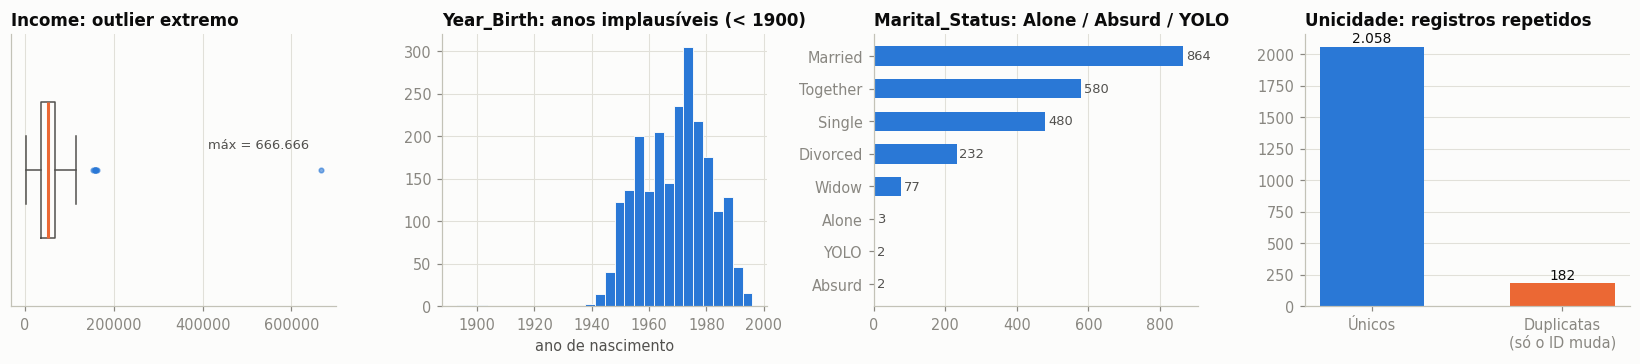

In [11]:
# ---- Confirmação dos achados previamente verificados (devem bater com a execução) ----
gastos = ["MntWines", "MntFruits", "MntMeatProducts", "MntFishProducts", "MntSweetProducts", "MntGoldProds"]
compras = raw[["NumWebPurchases", "NumCatalogPurchases", "NumStorePurchases"]].sum(axis=1)
achados = [
    ("Income tem 24 nulos", 24, int(raw["Income"].isna().sum())),
    ("Income máximo = 666.666", 666666, raw["Income"].max()),
    ("Year_Birth mínimo = 1893", 1893, raw["Year_Birth"].min()),
    ("Marital_Status contém Alone, Absurd e YOLO", True, {"Alone", "Absurd", "YOLO"} <= set(raw["Marital_Status"])),
    ("Education contém '2n Cycle'", True, "2n Cycle" in set(raw["Education"])),
    ("Z_CostContact constante = 3", 3, raw["Z_CostContact"].unique().tolist() == [3] and 3),
    ("Z_Revenue constante = 11", 11, raw["Z_Revenue"].unique().tolist() == [11] and 11),
    ("Sem duplicatas por linha inteira (ID incluso)", 0, int(raw.duplicated().sum())),
    ("Sem duplicatas por ID", 0, int(raw["ID"].duplicated().sum())),
    ("Registros duplicados exceto o ID = 182", 182, int(len(dup_raw))),
    ("Response ≈ 14,9%", 0.149, round(raw["Response"].mean(), 3)),
    ("Vinhos ≈ 50% do gasto", 0.50, round(raw["MntWines"].sum() / raw[gastos].sum().sum(), 3)),
    ("Loja física ≈ 46% das compras", 0.46, round(raw["NumStorePurchases"].sum() / compras.sum(), 3)),
]
conf = pd.DataFrame([{"achado": a, "esperado": e, "observado": o, "confere": (abs(o - e) < 0.006) if isinstance(e, float) else (o == e)} for a, e, o in achados])
display(conf)
if not conf["confere"].all():
    print("ATENÇÃO: há achados que não conferem — revise a versão do dataset antes de prosseguir.")
graf_qualidade(raw, len(dup_raw), salvar=BASE / "evidencias" / "qualidade_outliers_categorias.png")
plt.show()


## 6. Tratamento: decisões justificadas e regras de negócio
| Problema | Decisão | Justificativa |
|---|---|---|
| Registros repetidos com outro ID (**R11**) | Remover da Silver, mantendo o menor ID; a Bronze guarda tudo | Com 28 atributos idênticos a coincidência é improvável: dupla contagem distorceria K-Means, receita e taxas. `REMOVER_DUPLICATAS=False` mantém e apenas sinaliza |
| `Income` nulo (24) (**R3**) | Imputar pela **mediana de renda do mesmo nível de educação** | Renda varia com escolaridade; a mediana é robusta a outliers. `flag_renda_imputada` preserva a rastreabilidade |
| `Income` = 666.666 (**R4**) | Erro de digitação (> Q3 + 3·IQR) → nulo → imputar | É ~4× o segundo maior valor; distorceria média, escala e K-Means |
| `Year_Birth` < 1900 (**R5**) | Idade > 100 → imputar mediana | Poucos casos; remover perderia o cliente. `flag_idade_corrigida` |
| Idade e tempo de cliente (**R2**) | Calcular em relação à **maior `Dt_Customer`** | Dados de 2012–2014; usar a data de hoje inflaria a idade de todos |
| `Marital_Status` Alone/Absurd/YOLO (**R6**) | Alone → Solteiro(a); Absurd e YOLO → "Não informado" | Evita inventar valor; preserva a coluna original |
| `Education` "2n Cycle" (**R7**) | Padronizar como Mestrado (premissa), mantendo o original | 2º ciclo (Bologna) ≈ mestrado |
| `Z_CostContact`, `Z_Revenue` (**R1**) | Descartar da Silver; usar como **premissa** de P4 | Constantes: sem poder discriminante |
| Compras com desconto > compras totais (**R9**), clientes sem compras (**R10**) | Manter e sinalizar; limitar % a 1 | Inconsistências pequenas, registradas |

A lógica fica em **funções reutilizadas no Colab e no Databricks** (`scripts/mvp_core.py`).


In [12]:
bronze = pd.read_csv(destino, sep="\t", dtype=str)   # como a Bronze: tudo texto
silver, log_regras, constantes, duplicatas = silver_transform(bronze, remover_duplicatas=REMOVER_DUPLICATAS)
log_regras.to_csv(BASE / "catalogo" / "regras_transformacao.csv", index=False)
print("Silver local:", silver.shape, "| Bronze:", bronze.shape, "| nulos restantes:", int(silver.isna().sum().sum()))
print("Constantes descartadas (premissa de P4):", constantes)
display(log_regras)

Silver local: (2058, 53) | Bronze: (2240, 29) | nulos restantes: 0
Constantes descartadas (premissa de P4): {'Z_CostContact': 3.0, 'Z_Revenue': 11.0}


,regra,afetados,decisao
0,R1 Colunas constantes,2,"Descartadas ['Z_CostContact', 'Z_Revenue'] (va..."
1,R2 Data de referência,2058,data_ref = max(Dt_Customer) = 2014-06-29; idad...
2,R3 Renda nula,24,Imputada pela mediana de renda do mesmo nível ...
3,R4 Renda outlier extremo,1,"Valores > 167,338 (Q3+3·IQR) tratados como err..."
4,R5 Idade implausível,3,Idade > 100 ou < 16 na data de referência vira...
5,R6 Estado civil,7,Alone -> Solteiro(a); Absurd e YOLO -> 'Não in...
6,R7 Educação '2n Cycle',188,Premissa: 2º ciclo (Bologna) equivale a Mestra...
7,R8 Features,2058,"gasto_total, compras_total (web+catálogo+loja;..."
8,R9 Consistência: compras com desconto > compra...,3,Mantidos; pct_compras_desconto limitado a 1 (i...
9,R10 Clientes sem compras,6,Mantidos (têm gasto > 0); ticket médio e share...



## 7. Modelagem — constelação de fatos (esquema estrela estendido)
**Por que estrela:** P1–P5 são métricas (gasto, compras, campanhas) cortadas por atributos descritivos; o estrela dá joins simples e SQL legível. Como há mais de um grão de análise, o modelo é uma **constelação de fatos**:

| Tabela | Tipo | Grão / conteúdo |
|---|---|---|
| `fato_cliente_vendas` | fato | um cliente: gasto, compras por canal, desconto, visitas web, recência, campanhas, FKs |
| `fato_campanha_resposta` | fato | cliente × campanha (6 campanhas): aceitou (0/1) |
| `fato_gasto_categoria` | fato | cliente × categoria (6 categorias): gasto |
| `dim_cliente`, `dim_educacao`, `dim_estado_civil`, `dim_tempo`, `dim_segmento`, `dim_campanha`, `dim_categoria` | dimensões | atributos descritivos |

Abaixo roda-se o **ensaio local** da clusterização e da construção do modelo (os mesmos códigos executam no Databricks).


k escolhido = 3 | silhouette = 0.263  (k=2 teria 0.335)
Estabilidade entre sementes [1, 7, 21, 42, 99]: ARI médio = 0.999 | mínimo = 0.998
Estabilidade bootstrap (30 reamostragens): ARI médio = 0.853 | percentil 5 = 0.406


,k,inercia,silhouette,davies_bouldin,calinski_harabasz
0,2,7626.004,0.335,1.211,1273.072
1,3,6674.621,0.263,1.482,873.371
2,4,5856.096,0.217,1.682,759.002
3,5,5289.133,0.219,1.535,684.982
4,6,4835.794,0.207,1.461,637.539
5,7,4427.742,0.216,1.381,611.478
6,8,4182.346,0.219,1.331,571.777


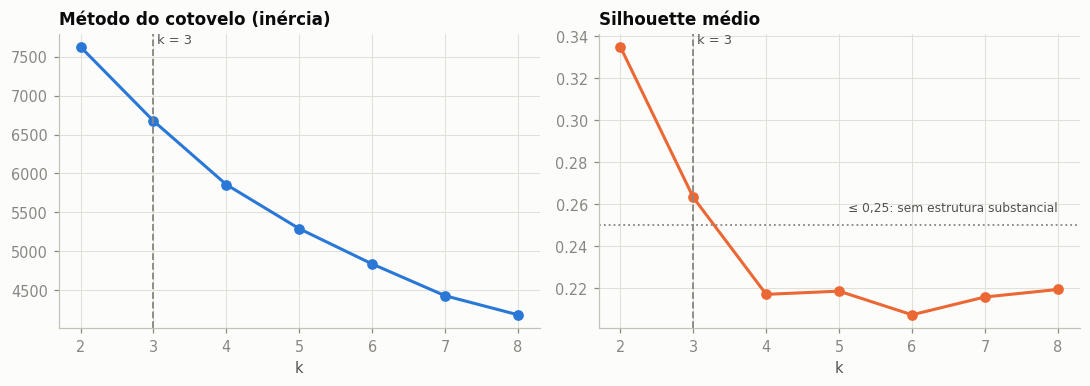

,verificação,ok
0,PK única: dim_cliente.cliente_id,True
1,PK única: dim_educacao.educacao_id,True
2,PK única: dim_estado_civil.estado_civil_id,True
3,PK única: dim_tempo.data_id,True
4,PK única: dim_segmento.segmento_id,True
5,PK única: dim_campanha.campanha_id,True
6,PK única: dim_categoria.categoria_id,True
7,PK única: fato_cliente_vendas.cliente_id,True
8,FK sem órfãos: fato_cliente_vendas.cliente_id ...,True
9,FK sem órfãos: fato_cliente_vendas.educacao_id...,True


dim_cliente              (2058, 13)
dim_educacao             (5, 4)
dim_estado_civil         (6, 3)
dim_tempo                (663, 7)
dim_segmento             (3, 6)
dim_campanha             (6, 4)
dim_categoria            (6, 4)
fato_cliente_vendas      (2058, 40)
fato_campanha_resposta   (12348, 5)
fato_gasto_categoria     (12348, 4)


In [13]:
seg_id, metricas, estab = clusterizar(silver, k_max=K_MAX, k_min_escolha=K_MIN_ESCOLHA, seed=SEED)
gold = construir_gold(silver, seg_id)
print(f"k escolhido = {estab['k']} | silhouette = {estab['silhouette_k']:.3f}  (k=2 teria {estab['silhouette_k2']:.3f})")
print(f"Estabilidade entre sementes {estab['sementes']}: ARI médio = {estab['ari_medio']:.3f} | mínimo = {estab['ari_min']:.3f}")
print(f"Estabilidade bootstrap ({estab['boot_n']} reamostragens): ARI médio = {estab['boot_ari_medio']:.3f} | percentil 5 = {estab['boot_ari_p05']:.3f}")
display(metricas.round(3))
graf_escolha_k(metricas, estab["k"], salvar=BASE / "evidencias" / "ensaio_local_escolha_k.png"); plt.show()
display(checar_integridade(gold))
for nome, df_ in gold.items():
    print(f"{nome:24s} {df_.shape}")

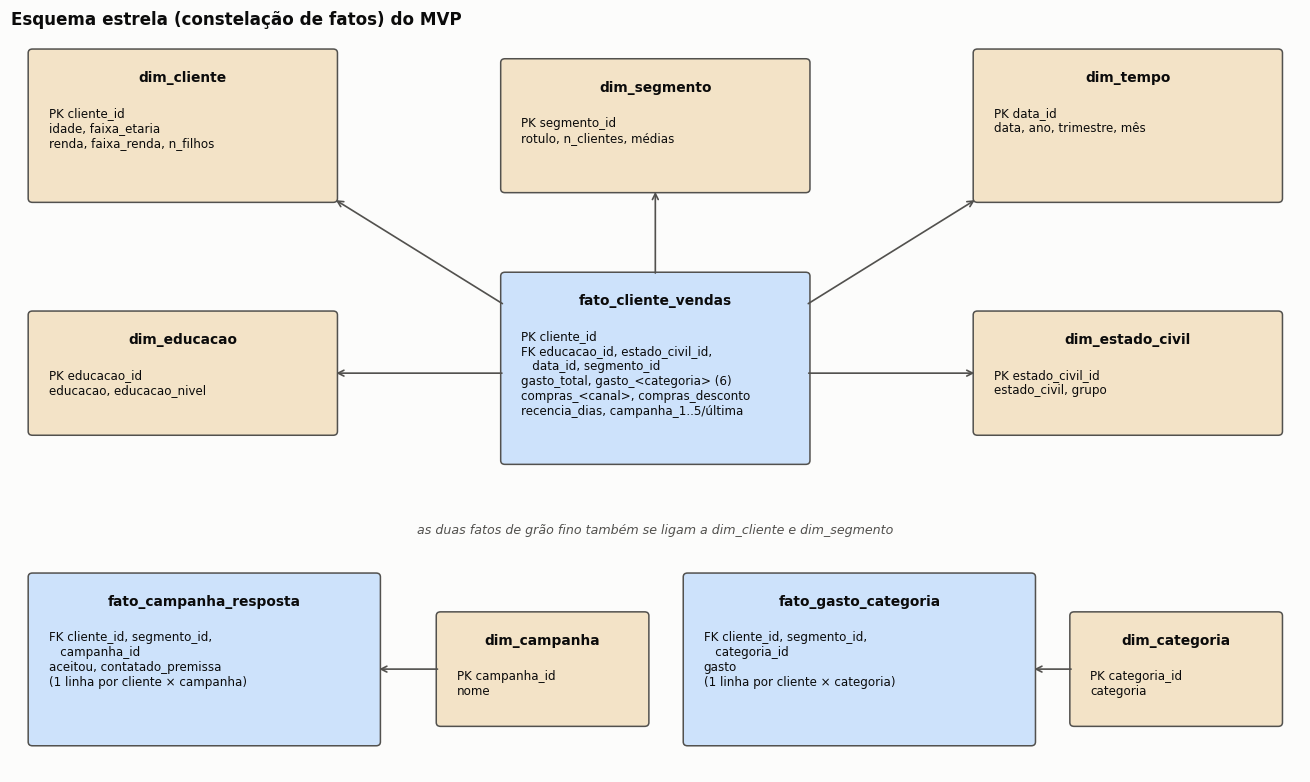

In [14]:
# Diagrama do modelo: mermaid (.md) e imagem (.png) em /catalogo
(BASE / "catalogo" / "diagrama_estrela.md").write_text("# Diagrama do modelo (constelação de fatos)\n\n" + MERMAID_ESTRELA, encoding="utf-8")
graf_estrela(salvar=BASE / "catalogo" / "diagrama_estrela.png"); plt.show()

## 8. Catálogo de dados (CSV e Markdown)
Campos exigidos pelo PDF (seção 3.3): nome, tipo, descrição, domínio (mín/máx ou categorias), obrigatoriedade (nulos e significado da ausência) e linhagem (origem, data de extração, transformações). Domínios e obrigatoriedade são **calculados dos dados**; descrições são texto de negócio.

In [15]:
EXTRACAO = meta["data_coleta_utc"][:10]
linhas_cat = catalogar("bronze_marketing_campaign", raw, EXTRACAO)
linhas_cat += catalogar("silver_clientes", silver, EXTRACAO)
for nome, df_ in gold.items():
    linhas_cat += catalogar(nome, df_, EXTRACAO)
catalogo = pd.DataFrame(linhas_cat)
faltando = catalogo[catalogo["descricao"] == "[sem descrição]"]["atributo"].unique().tolist()
assert not faltando, f"Atributos sem descrição no catálogo: {faltando}"
catalogo.to_csv(BASE / "catalogo" / "catalogo_dados.csv", index=False, encoding="utf-8")
(BASE / "catalogo" / "catalogo_dados.md").write_text(catalogo_markdown(catalogo, KAGGLE_DATASET, LICENCA_DADOS, EXTRACAO), encoding="utf-8")
print(f"Catálogo: {len(catalogo)} atributos em {catalogo['tabela'].nunique()} tabelas")
catalogo.head(12)

Catálogo: 172 atributos em 12 tabelas


,tabela,atributo,tipo,descricao,dominio,obrigatoriedade,linhagem
0,bronze_marketing_campaign,ID,numérico (chave),Identificador sequencial do cliente (não é ide...,"inteiro, 0 a 11191, únicos=2240",Obrigatório (0 nulos),Kaggle imakash3011/customer-personality-analys...
1,bronze_marketing_campaign,Year_Birth,numérico,Ano de nascimento,1893 a 1996,Obrigatório (0 nulos),Kaggle imakash3011/customer-personality-analys...
2,bronze_marketing_campaign,Education,categórico,Nível de escolaridade,2n Cycle; Basic; Graduation; Master; PhD,Obrigatório (0 nulos),Kaggle imakash3011/customer-personality-analys...
3,bronze_marketing_campaign,Marital_Status,categórico,Estado civil,Absurd; Alone; Divorced; Married; Single; Toge...,Obrigatório (0 nulos),Kaggle imakash3011/customer-personality-analys...
4,bronze_marketing_campaign,Income,numérico,Renda anual do domicílio,1730 a 666666,Admite nulos (24); ausência = valor não inform...,Kaggle imakash3011/customer-personality-analys...
5,bronze_marketing_campaign,Kidhome,numérico,Nº de crianças no domicílio,0 a 2,Obrigatório (0 nulos),Kaggle imakash3011/customer-personality-analys...
6,bronze_marketing_campaign,Teenhome,numérico,Nº de adolescentes no domicílio,0 a 2,Obrigatório (0 nulos),Kaggle imakash3011/customer-personality-analys...
7,bronze_marketing_campaign,Dt_Customer,texto,Data de cadastro do cliente (dd-mm-aaaa),663 valores distintos,Obrigatório (0 nulos),Kaggle imakash3011/customer-personality-analys...
8,bronze_marketing_campaign,Recency,numérico,Dias desde a última compra,0 a 99,Obrigatório (0 nulos),Kaggle imakash3011/customer-personality-analys...
9,bronze_marketing_campaign,MntWines,numérico,Gasto com vinhos nos últimos 2 anos,0 a 1493,Obrigatório (0 nulos),Kaggle imakash3011/customer-personality-analys...



## 9. Notebooks Databricks (Bronze → Silver → Gold → Análise)
As quatro células abaixo gravam os **modelos** dos notebooks (formato `# Databricks notebook source`). A célula seguinte preenche os parâmetros da seção 3 e insere o núcleo (`mvp_core`), a camada de análise (`mvp_analise`) e as visões (`mvp_views`); valida a sintaxe e salva cada notebook em **`.py` (importável no Databricks) e `.ipynb`**, em `databricks/` e `notebooks/`.

| Notebook | Camada | O que faz |
|---|---|---|
| `01_bronze_ingestao` | Bronze | CSV bruto do Volume → Delta, sem alterações + metadados de ingestão, hash e conferência de forma |
| `02_silver_limpeza_features` | Silver | qualidade por atributo/dimensão, regras R1–R11, features; grava log de regras, constantes e duplicatas removidas |
| `03_gold_estrela_cluster` | Gold | K-Means (silhouette, estabilidade), constelação de fatos, integridade, visões analíticas, catálogo + comentários de coluna |
| `04_analise_p1_p5` | Análise | P1–P5 com SQL/pandas, gráficos e **discussão gerada dos números da execução**, playbook e limitações |


In [16]:
%%writefile databricks/_templates/01_bronze_ingestao.py
# Databricks notebook source
# MAGIC %md
# MAGIC # 01 · Bronze — ingestão do CSV bruto
# MAGIC **Objetivo:** ler `marketing_campaign.csv` (separado por TAB) do Volume do Unity Catalog e gravar em Delta **sem nenhuma alteração de conteúdo**.
# MAGIC Todas as colunas entram como texto (sem inferência de tipos), mais metadados de ingestão (`_ingestao_ts`, `_arquivo_origem`, `_lote_id`).
# MAGIC Tipagem e limpeza ficam para a camada Silver. A Bronze **preserva todos os registros**, inclusive duplicatas.

# COMMAND ----------

# {{CONFIG}}

# COMMAND ----------

# 1. Garante schema e volume (idempotente)
import os, uuid, hashlib
from pyspark.sql import functions as F

spark.sql(f"CREATE SCHEMA IF NOT EXISTS {CATALOG}.{SCHEMA}")
spark.sql(f"CREATE VOLUME IF NOT EXISTS {CATALOG}.{SCHEMA}.{VOLUME}")
caminho = f"/Volumes/{CATALOG}/{SCHEMA}/{VOLUME}/{CSV_NAME}"
print("Arquivo esperado:", caminho)

# COMMAND ----------

# 2. Verifica se o CSV foi enviado ao Volume e registra tamanho e hash (reprodutibilidade)
if not os.path.exists(caminho):
    raise FileNotFoundError(
        f"CSV não encontrado em {caminho}. Envie o arquivo pela interface: "
        "Catalog > {CATALOG} > {SCHEMA} > {VOLUME} > Upload to this volume.".format(
            CATALOG=CATALOG, SCHEMA=SCHEMA, VOLUME=VOLUME))
print("Tamanho (bytes):", os.path.getsize(caminho))
print("sha256:", hashlib.sha256(open(caminho, "rb").read()).hexdigest())

# COMMAND ----------

# 3. Leitura bruta (tudo string) + metadados de ingestão
df = (spark.read.option("header", True).option("sep", "\t").option("inferSchema", False).csv(caminho))
df = (df.withColumn("_ingestao_ts", F.current_timestamp())
        .withColumn("_arquivo_origem", F.lit(caminho))
        .withColumn("_lote_id", F.lit(str(uuid.uuid4()))))

n = df.count()
print(f"Linhas: {n} | Colunas (com metadados): {len(df.columns)}")
if n == 0:
    raise ValueError("Bronze vazio: verifique o separador (TAB) e o arquivo.")
if (n, len(df.columns) - 3) != (2240, 29):
    print(f"ATENÇÃO: esperado (2240, 29), obtido ({n}, {len(df.columns) - 3}). Verifique se é a mesma versão do dataset.")

# COMMAND ----------

# 4. Grava Delta (overwrite para o job ser reexecutável)
(df.write.format("delta").mode("overwrite").option("overwriteSchema", "true")
   .saveAsTable(T("bronze_marketing_campaign")))
print("Tabela criada:", T("bronze_marketing_campaign"))
display(spark.sql(f"SELECT * FROM {T('bronze_marketing_campaign')} LIMIT 5"))

# COMMAND ----------

# 5. Evidência: histórico Delta e contagem
display(spark.sql(f"DESCRIBE HISTORY {T('bronze_marketing_campaign')}"))
display(spark.sql(f"SELECT COUNT(*) AS linhas FROM {T('bronze_marketing_campaign')}"))

Writing databricks/_templates/01_bronze_ingestao.py


In [17]:
%%writefile databricks/_templates/02_silver_limpeza_features.py
# Databricks notebook source
# MAGIC %md
# MAGIC # 02 · Silver — tipagem, qualidade e features
# MAGIC Lê a Bronze, mede a **qualidade por atributo e por dimensão**, aplica as regras de negócio documentadas (R1–R11) e grava `silver_clientes`, mais tabelas de apoio:
# MAGIC `silver_regras_negocio` (cada regra e quantos registros afetou), `silver_constantes` (valores das colunas constantes descartadas, usados como premissa em P4),
# MAGIC `silver_duplicatas_removidas`, `silver_qualidade_atributos` e `silver_qualidade_testes`.
# MAGIC
# MAGIC | Regra | O que faz |
# MAGIC |---|---|
# MAGIC | R1 | Descarta colunas constantes (`Z_CostContact`, `Z_Revenue`) |
# MAGIC | R2 | Data de referência = maior `Dt_Customer` (não a data de hoje) |
# MAGIC | R3/R4 | Renda nula ou outlier extremo (> Q3 + 3·IQR) → imputada pela mediana do nível de educação |
# MAGIC | R5 | Idade > 100 ou < 16 → imputada pela mediana |
# MAGIC | R6/R7 | Padroniza estado civil e educação |
# MAGIC | R8–R10 | Features derivadas e checagens de consistência |
# MAGIC | R11 | Registros idênticos em todos os atributos exceto o ID (duplicatas re-chaveadas) → removidos da Silver (a Bronze os preserva) |

# COMMAND ----------

# {{CONFIG}}

# COMMAND ----------

# ---- Núcleo de lógica (mesmo código usado no Colab) ----
# {{CORE}}

# COMMAND ----------

# 1. Lê a Bronze (volume pequeno: converter para pandas é seguro e simplifica as regras)
bronze = spark.table(T("bronze_marketing_campaign")).toPandas()
print("Bronze:", bronze.shape)

# COMMAND ----------

# 2. Qualidade de dados sobre o dado bruto (por atributo e por dimensão)
raw_t = tipar_bronze(bronze)
q_atrib = perfil_atributos(raw_t)
q_testes = testes_qualidade(raw_t)
display(q_atrib)
display(q_testes)

# COMMAND ----------

# 3. Aplica as regras de negócio (lógica em silver_transform)
silver, log_regras, constantes, duplicatas = silver_transform(bronze, remover_duplicatas=REMOVER_DUPLICATAS)
print("Silver:", silver.shape)
display(log_regras)

# COMMAND ----------

# 4. Checagens automáticas antes de gravar
n_esperado = len(bronze) - (len(duplicatas) if REMOVER_DUPLICATAS else 0)
assert len(silver) == n_esperado, "Silver perdeu/duplicou linhas além das duplicatas removidas"
assert silver["cliente_id"].is_unique, "cliente_id duplicado"
assert silver.isna().sum().sum() == 0, "Silver não deveria ter nulos após o tratamento"
assert (silver["gasto_total"] >= 0).all()
print("Checagens OK")

# COMMAND ----------

# 5. Grava Delta
import pandas as pd

def gravar(pdf, nome):
    (spark.createDataFrame(pdf).write.format("delta").mode("overwrite")
          .option("overwriteSchema", "true").saveAsTable(T(nome)))

gravar(silver, "silver_clientes")
gravar(log_regras.astype(str), "silver_regras_negocio")
gravar(pd.DataFrame({"coluna": list(constantes.keys()), "valor": list(constantes.values())}), "silver_constantes")
gravar(duplicatas if len(duplicatas) else pd.DataFrame({"cliente_id_removido": pd.Series(dtype="int64"),
       "cliente_id_mantido": pd.Series(dtype="int64"), "grupo": pd.Series(dtype="int64")}), "silver_duplicatas_removidas")
gravar(q_atrib.astype(str), "silver_qualidade_atributos")
gravar(q_testes.astype(str), "silver_qualidade_testes")
display(spark.sql(f"SELECT COUNT(*) AS linhas FROM {T('silver_clientes')}"))

Writing databricks/_templates/02_silver_limpeza_features.py


In [18]:
%%writefile databricks/_templates/03_gold_estrela_cluster.py
# Databricks notebook source
# MAGIC %md
# MAGIC # 03 · Gold — esquema estrela, clusterização e visões analíticas
# MAGIC 1. Clusteriza os clientes com **K-Means** sobre RFM + perfil (`recencia_dias`, `compras_total`, `log(gasto_total)`, `renda`, `idade`, `n_filhos`), padronizados (z-score).
# MAGIC 2. Escolhe **k** pelo maior *silhouette* entre `K_MIN_ESCOLHA` e `K_MAX` (inércia, Davies–Bouldin e Calinski–Harabasz como apoio) e mede a **estabilidade** com 5 sementes (ARI) e com reamostragem bootstrap.
# MAGIC 3. Grava o esquema estrela (constelação de fatos): `fato_cliente_vendas`, `fato_campanha_resposta`, `fato_gasto_categoria` e as dimensões `dim_cliente`, `dim_educacao`, `dim_estado_civil`, `dim_tempo`, `dim_segmento`, `dim_campanha`, `dim_categoria`; verifica a integridade (PK/FK e totais).
# MAGIC 4. Cria as visões analíticas usadas em `04_analise` e grava o **catálogo de dados** (`gold_catalogo_dados` + comentários de coluna no Unity Catalog).

# COMMAND ----------

# {{CONFIG}}

# COMMAND ----------

# ---- Núcleo de lógica (mesmo código usado no Colab) ----
# {{CORE}}

# COMMAND ----------

# ---- Visões SQL (mesmo código usado no Colab/DuckDB) ----
# {{VIEWS}}

# COMMAND ----------

# 1. Lê Silver e clusteriza
silver = spark.table(T("silver_clientes")).toPandas()
seg_id, metricas, estab = clusterizar(silver, k_max=K_MAX, k_min_escolha=K_MIN_ESCOLHA, seed=SEED)
print("k escolhido:", estab["k"], "| silhouette:", round(estab["silhouette_k"], 3))
print("Estabilidade (ARI entre sementes): média", round(estab["ari_medio"], 3), "| mínimo", round(estab["ari_min"], 3))
print("Estabilidade bootstrap: ARI médio", round(estab["boot_ari_medio"], 3), "| percentil 5", round(estab["boot_ari_p05"], 3))
display(metricas)

# COMMAND ----------

# 2. Constrói, verifica e grava o esquema estrela
import pandas as pd

def gravar(pdf, nome):
    (spark.createDataFrame(pdf).write.format("delta").mode("overwrite")
          .option("overwriteSchema", "true").saveAsTable(T(nome)))

gold = construir_gold(silver, seg_id)
display(checar_integridade(gold))
ordem = ["dim_cliente", "dim_educacao", "dim_estado_civil", "dim_tempo", "dim_segmento", "dim_campanha", "dim_categoria",
         "fato_cliente_vendas", "fato_campanha_resposta", "fato_gasto_categoria"]
for nome in ordem:
    gravar(gold[nome], nome)
    print(f"{nome}: {len(gold[nome])} linhas")

# métricas da clusterização e estabilidade (apoiam a justificativa de k)
gravar(metricas, "gold_clusterizacao_metricas")
estab_df = pd.DataFrame([{"k": estab["k"], "silhouette": estab["silhouette_k"], "ari_medio": estab["ari_medio"],
                          "ari_min": estab["ari_min"], "boot_ari_medio": estab["boot_ari_medio"],
                          "boot_ari_p05": estab["boot_ari_p05"], "boot_n": estab["boot_n"],
                          "sementes": str(estab["sementes"]), "seed_base": SEED}])
gravar(estab_df, "gold_clusterizacao_estabilidade")

# premissas de P4 (Z_* são premissa: a base não documenta o significado)
const = {r["coluna"]: r["valor"] for r in spark.table(T("silver_constantes")).collect()}
prem = pd.DataFrame([{"custo_contato": const["Z_CostContact"], "receita_aceite": const["Z_Revenue"],
                      "contatos_por_cliente": N_CONTATOS_POR_CLIENTE}])
gravar(prem, "gold_premissas_p4")
display(prem)

# COMMAND ----------

# 3. Visões analíticas por segmento (SQL)
for nome_view, consulta in sql_views(T, lambda col, p: f"percentile_approx({col}, {p})", PCT_RISCO_GASTO, PCT_RISCO_RECENCIA).items():
    spark.sql(f"CREATE OR REPLACE VIEW {T(nome_view)} AS {consulta}")
    print("visão criada:", T(nome_view))
display(spark.sql(f"SELECT * FROM {T('vw_perfil_segmento')} ORDER BY segmento_id"))

# COMMAND ----------

# 4. Catálogo de dados (descrição, domínio, obrigatoriedade, linhagem) + comentários de coluna no Unity Catalog
import datetime as dt
extracao = dt.date.today().isoformat()
raw_t = tipar_bronze(spark.table(T("bronze_marketing_campaign")).toPandas())
linhas = catalogar("bronze_marketing_campaign", raw_t, extracao) + catalogar("silver_clientes", silver, extracao)
for nome in ordem:
    linhas += catalogar(nome, gold[nome], extracao)
catalogo = pd.DataFrame(linhas)
faltando = catalogo[catalogo["descricao"] == "[sem descrição]"]["atributo"].unique().tolist()
assert not faltando, f"Atributos sem descrição no catálogo: {faltando}"
gravar(catalogo, "gold_catalogo_dados")

ok = 0
for r in catalogo[catalogo["tabela"] != "bronze_marketing_campaign"].itertuples():
    try:
        spark.sql(f"ALTER TABLE {T(r.tabela)} ALTER COLUMN `{r.atributo}` COMMENT '{r.descricao.replace(chr(39), '')}'")
        ok += 1
    except Exception:
        pass   # o catálogo também fica na tabela gold_catalogo_dados; comentário é bônus
print(f"Catálogo: {len(catalogo)} atributos em {catalogo['tabela'].nunique()} tabelas | comentários de coluna gravados: {ok}")
display(catalogo.head(12))

Writing databricks/_templates/03_gold_estrela_cluster.py


In [19]:
%%writefile databricks/_templates/04_analise_p1_p5.py
# Databricks notebook source
# MAGIC %md
# MAGIC # 04 · Análise — respostas a P1–P5
# MAGIC Cada seção traz: consulta (SQL/pandas) → gráfico → **discussão gerada dos números desta execução** (nada digitado à mão).
# MAGIC Resultados fracos ou inconclusivos são relatados como tal. Depende dos notebooks 01–03.

# COMMAND ----------

# {{CONFIG}}

# COMMAND ----------

# ---- Camada de análise (gráficos, estatística e discussões) ----
# {{ANALISE}}

# COMMAND ----------

import pandas as pd, numpy as np
def q(sql):
    return spark.sql(sql).toPandas()

silver = spark.table(T("silver_clientes")).toPandas()
fato = spark.table(T("fato_cliente_vendas")).toPandas()
perfil = q(f"SELECT * FROM {T('vw_perfil_segmento')} ORDER BY segmento_id")
rotulos = dict(zip(perfil["segmento_id"], perfil["rotulo"]))
sil_seg = silver.merge(fato[["cliente_id", "segmento_id"]], on="cliente_id")      # silver + segmento (nível do cliente)
seg_id = sil_seg["segmento_id"].values
metricas = q(f"SELECT * FROM {T('gold_clusterizacao_metricas')} ORDER BY k")
est_df = q(f"SELECT * FROM {T('gold_clusterizacao_estabilidade')}")
estab = estab_de_tabelas(est_df, metricas, K_MIN_ESCOLHA, K_MAX)
prem = q(f"SELECT * FROM {T('gold_premissas_p4')}")
CUSTO_CONTATO, RECEITA_ACEITE = float(prem["custo_contato"].iloc[0]), float(prem["receita_aceite"].iloc[0])
print(f"{len(silver)} clientes | k = {estab['k']}")

# COMMAND ----------

# MAGIC %md
# MAGIC ## Qualidade dos dados (medida na Silver, sobre o dado bruto)

# COMMAND ----------

display(q(f"SELECT * FROM {T('silver_qualidade_testes')}"))
display(q(f"SELECT * FROM {T('silver_regras_negocio')}"))

# COMMAND ----------

# MAGIC %md
# MAGIC ## P1 · Quantos segmentos naturais existem e qual o perfil de cada um?

# COMMAND ----------

graf_escolha_k(metricas, estab["k"])
display(metricas); display(est_df)

# COMMAND ----------

graf_pca(sil_seg, seg_id, rotulos)
display(perfil)
graf_perfil(perfil)
d_seg, carac = caracterizar_segmentos(sil_seg)
tseg = testes_segmentos(sil_seg)
display(tseg)
mostrar_md(disc_p1(estab, perfil, carac, tseg))

# COMMAND ----------

# MAGIC %md
# MAGIC ## P2 · Contribuição de cada segmento para a receita e concentração (Pareto 80%)

# COMMAND ----------

rec = q(f"SELECT * FROM {T('vw_receita_segmento')} ORDER BY segmento_id")
par = pareto(sil_seg["gasto_total"])
display(rec)
graf_receita_pareto(rec, par)
mostrar_md(disc_p2(rec, par))

# COMMAND ----------

# MAGIC %md
# MAGIC ## P3 · Mix de categorias, canais, visitas web e compras com desconto

# COMMAND ----------

mix = q(f"SELECT * FROM {T('vw_mix_canal_segmento')} ORDER BY segmento_id")
display(mix)
graf_mix_canal(mix)
graf_visitas_desconto(mix)
glob = globais_mix(silver)
corr = correlacoes_associacao(sil_seg)
display(corr)
mostrar_md(disc_p3(mix, glob, corr))

# COMMAND ----------

# MAGIC %md
# MAGIC ## P4 · Aceitação de campanhas e retorno estimado por segmento
# MAGIC **Premissa declarada:** a base **não documenta** `Z_CostContact` e `Z_Revenue`. Assumimos custo por contato = `Z_CostContact` e receita por aceite = `Z_Revenue`, e que **cada cliente foi contatado nas 6 campanhas** (1 a 5 e a última). Os resultados abaixo dependem inteiramente dessa premissa.

# COMMAND ----------

fc = spark.table(T("fato_campanha_resposta")).toPandas()
dim_camp = spark.table(T("dim_campanha")).toPandas()
dim_seg = spark.table(T("dim_segmento")).toPandas()
g_sc, camp_seg = tabela_campanhas(fc, dim_camp, dim_seg, CUSTO_CONTATO, RECEITA_ACEITE)
camp_cmp = por_campanha(fc, dim_camp)
tc = testes_campanhas(fc, dim_camp)
v_camp = q(f"SELECT * FROM {T('vw_campanhas_segmento')} ORDER BY segmento_id")      # conferência cruzada com a visão SQL
assert (v_camp["aceites"].values == camp_seg.sort_values("segmento_id")["aceites"].values).all(), "visão SQL e fato longa divergem"
display(camp_seg); display(camp_cmp); display(tc)
BREAK_EVEN = CUSTO_CONTATO / RECEITA_ACEITE
graf_campanhas(g_sc, camp_seg, BREAK_EVEN)
mostrar_md(disc_p4(camp_seg, camp_cmp, g_sc, tc, CUSTO_CONTATO, RECEITA_ACEITE))

# COMMAND ----------

# MAGIC %md
# MAGIC ## P5 · Clientes de alto gasto e recência alta (risco de inatividade)
# MAGIC Definição: gasto total ≥ percentil `PCT_RISCO_GASTO` **e** dias desde a última compra ≥ percentil `PCT_RISCO_RECENCIA`. (Na base, `Recency` = dias desde a última compra; valor alto = cliente parado há mais tempo.)

# COMMAND ----------

risco = q(f"SELECT * FROM {T('vw_clientes_risco')} ORDER BY gasto_total DESC")
lim_g, lim_r = float(risco["lim_gasto"].iloc[0]), float(risco["lim_rec"].iloc[0])
n_base, gasto_base = len(silver), float(silver["gasto_total"].sum())
por_seg_risco = (risco.groupby("rotulo").agg(clientes=("cliente_id", "count"), gasto=("gasto_total", "sum"),
                                              recencia_media=("recencia_dias", "mean")).reset_index().sort_values("rotulo"))
print(f"{len(risco)} clientes em risco ({pct(len(risco) / n_base)} da base) | gasto somado: {br(risco['gasto_total'].sum())}")
display(risco.drop(columns=["lim_gasto", "lim_rec"]).head(20)); display(por_seg_risco)
graf_risco(sil_seg, lim_g, lim_r, por_seg_risco)
mostrar_md(disc_p5(risco, por_seg_risco, n_base, gasto_base, lim_g, lim_r, PCT_RISCO_GASTO, PCT_RISCO_RECENCIA))

# COMMAND ----------

# MAGIC %md
# MAGIC ## Discussão geral, playbook comercial e limitações

# COMMAND ----------

texto_geral, veredito = disc_geral(estab, tseg, camp_seg, tc, par)
mostrar_md(texto_geral)
mostrar_md(playbook(perfil, mix, rec, camp_seg, carac, por_seg_risco, len(risco), float(risco["gasto_total"].sum()), gasto_base))
n_dup = int(q(f"SELECT COUNT(*) AS n FROM {T('silver_duplicatas_removidas')}")["n"].iloc[0])
periodo = f"{silver['data_cadastro'].min().year}–{silver['data_cadastro'].max().year}"
mostrar_md(limitacoes(periodo, n_dup, REMOVER_DUPLICATAS))

Writing databricks/_templates/04_analise_p1_p5.py


In [20]:
# Gera os notebooks finais: preenche parâmetros e insere núcleo, análise e visões
import ast, nbformat
CONFIG_DBX = f"""# ---- Parâmetros (gerados a partir da seção 3 do Colab) ----
import warnings; warnings.filterwarnings("ignore")
CATALOG = "{CATALOG}"
SCHEMA = "{SCHEMA}"
VOLUME = "{VOLUME}"
CSV_NAME = "{CSV_NAME}"
SEED = {SEED}
K_MAX = {K_MAX}
K_MIN_ESCOLHA = {K_MIN_ESCOLHA}
PCT_RISCO_GASTO = {PCT_RISCO_GASTO}
PCT_RISCO_RECENCIA = {PCT_RISCO_RECENCIA}
N_CONTATOS_POR_CLIENTE = {N_CONTATOS_POR_CLIENTE}
REMOVER_DUPLICATAS = {REMOVER_DUPLICATAS}

def T(nome):
    return f"{{CATALOG}}.{{SCHEMA}}.{{nome}}"
"""
core_texto = (BASE / "scripts" / "mvp_core.py").read_text()
views_texto = (BASE / "scripts" / "mvp_views.py").read_text()
analise_texto = (BASE / "scripts" / "mvp_analise.py").read_text().split("\nexcept ImportError:\n    pass\n", 1)[1]   # sem o cabeçalho de import local

def py_para_ipynb(texto):
    texto = texto.replace("# Databricks notebook source\n", "", 1)
    celulas = []
    for bloco in texto.split("\n# COMMAND ----------\n"):
        bloco = bloco.strip("\n")
        if not bloco:
            continue
        linhas = bloco.splitlines()
        if linhas[0].startswith("# MAGIC"):
            fonte = "\n".join(l[len("# MAGIC "):] if l.startswith("# MAGIC ") else l[len("# MAGIC"):] for l in linhas)
            fonte = fonte.replace("%md\n", "", 1) if fonte.startswith("%md\n") else fonte
            celulas.append(nbformat.v4.new_markdown_cell(fonte))
        else:
            celulas.append(nbformat.v4.new_code_cell(bloco))
    nb = nbformat.v4.new_notebook(); nb["cells"] = celulas
    nb["metadata"] = {"kernelspec": {"display_name": "Python 3", "language": "python", "name": "python3"}, "language_info": {"name": "python"}}
    return nb

gerados = []
for tpl in sorted((BASE / "databricks" / "_templates").glob("*.py")):
    t = tpl.read_text()
    for marcador, conteudo in (("# {{CONFIG}}", CONFIG_DBX), ("# {{CORE}}", core_texto), ("# {{VIEWS}}", views_texto), ("# {{ANALISE}}", analise_texto)):
        t = t.replace(marcador, conteudo)
    sobra = [p for p in ("{{CONFIG}}", "{{CORE}}", "{{VIEWS}}", "{{ANALISE}}") if p in t]
    if sobra:
        raise ValueError(f"Placeholders não preenchidos em {tpl.name}: {sobra}")
    codigo = "\n".join(l for l in t.splitlines() if not l.startswith("# MAGIC"))
    ast.parse(codigo)                      # valida a sintaxe antes de entregar
    nb_ = py_para_ipynb(t)
    for celula in nb_["cells"]:
        if celula["cell_type"] == "code":
            ast.parse("\n".join(l for l in celula["source"].splitlines() if not l.startswith("%")))
    for pasta in ["databricks", "notebooks"]:
        (BASE / pasta / tpl.name).write_text(t, encoding="utf-8")
        nbformat.write(nb_, BASE / pasta / (tpl.stem + ".ipynb"))
    gerados.append(f"{tpl.stem}  ({len(t.splitlines())} linhas, {len(nb_['cells'])} células)")
print("Notebooks Databricks gerados (.py e .ipynb) e validados:", *gerados, sep="\n  - ")

Notebooks Databricks gerados (.py e .ipynb) e validados:
  - 01_bronze_ingestao  (77 linhas, 7 células)
  - 02_silver_limpeza_features  (632 linhas, 8 células)
  - 03_gold_estrela_cluster  (741 linhas, 8 células)
  - 04_analise_p1_p5  (864 linhas, 19 células)


## 10. Levar os dados e notebooks ao Databricks (Free Edition)

### Plano A — manual pela interface (recomendado, mais confiável)
1. Crie sua conta em **Databricks Free Edition** e abra o workspace.
2. **Notebooks:** *Workspace → Import* e envie os 4 arquivos `.py` de `databricks/` (ou os `.ipynb`) (formato *source* é reconhecido automaticamente).
3. **CSV:** em *Catalog* abra `workspace` (ou seu catálogo) → crie o schema `mvp_marketing` e o volume `raw` (o notebook 01 também cria, se não existirem) → **Upload to this volume** → envie `marketing_campaign.csv`.
4. Execute os notebooks **01 → 02 → 03 → 04** (computação serverless). Confira se `CATALOG` no topo bate com o seu catálogo.
5. **Job (valoriza o ETL):** *Jobs & Pipelines → Create job*, com 4 tarefas encadeadas (Bronze → Silver → Gold → Análise) apontando para os notebooks. O arquivo `databricks/job_definition.json` gerado abaixo traz a definição.

### Plano B — se algo falhar no Free Edition
Limitações comuns: não há clusters próprios (só serverless), cotas diárias de computação, e criação de catálogos/DBFS público restrita. Se o upload ao Volume falhar, grave em *Catalog → Create table → Upload file* e ajuste a leitura do notebook 01; se o job não puder ser criado, rode os notebooks em sequência e mostre o histórico de execução como evidência.

### Plano C — automatizado via Databricks SDK (opcional)
Defina `USAR_SDK = True` na seção 3. Usa token pessoal (Settings → Developer → Access tokens) lido por `getpass` — **nunca** escreva o token no notebook.

In [21]:
# Definição do job (Bronze > Silver > Gold > Análise) para criação manual ou via SDK
ordem_tarefas = ["01_bronze_ingestao", "02_silver_limpeza_features", "03_gold_estrela_cluster", "04_analise_p1_p5"]
def definicao_job(pasta_workspace):
    tarefas = []
    for i, n in enumerate(ordem_tarefas):
        t = {"task_key": n, "notebook_task": {"notebook_path": f"{pasta_workspace}/{n}"}}
        if i: t["depends_on"] = [{"task_key": ordem_tarefas[i - 1]}]
        tarefas.append(t)
    return {"name": "MVP_UnB_Pipeline_Medalhao", "tasks": tarefas, "queue": {"enabled": True}}
job_json = definicao_job("/Workspace/Users/<seu-usuario>/mvp_unb")   # ajuste o usuário se criar manualmente
(BASE / "databricks" / "job_definition.json").write_text(json.dumps(job_json, indent=2))
print(json.dumps(job_json, indent=2)[:700], "...")

{
  "name": "MVP_UnB_Pipeline_Medalhao",
  "tasks": [
    {
      "task_key": "01_bronze_ingestao",
      "notebook_task": {
        "notebook_path": "/Workspace/Users/<seu-usuario>/mvp_unb/01_bronze_ingestao"
      }
    },
    {
      "task_key": "02_silver_limpeza_features",
      "notebook_task": {
        "notebook_path": "/Workspace/Users/<seu-usuario>/mvp_unb/02_silver_limpeza_features"
      },
      "depends_on": [
        {
          "task_key": "01_bronze_ingestao"
        }
      ]
    },
    {
      "task_key": "03_gold_estrela_cluster",
      "notebook_task": {
        "notebook_path": "/Workspace/Users/<seu-usuario>/mvp_unb/03_gold_estrela_cluster"
      },
      "depends_on": ...


In [22]:
# Plano C (opcional): envio automático via Databricks SDK
if not USAR_SDK:
    print("USAR_SDK = False -> use o Plano A (manual). Nada foi enviado.")
else:
    from getpass import getpass
    import base64
    try:
        from databricks.sdk import WorkspaceClient
        from databricks.sdk.service.workspace import ImportFormat, Language
        from databricks.sdk.service import jobs as dj
        host = input("URL do workspace (ex.: https://dbc-xxxx.cloud.databricks.com): ").strip()
        token = getpass("Token pessoal do Databricks (não será exibido): ")
        w = WorkspaceClient(host=host, token=token)
        usuario = w.current_user.me().user_name
        print("Autenticado como:", usuario)

        # schema e volume
        for criar in (lambda: w.schemas.create(name=SCHEMA, catalog_name=CATALOG),
                      lambda: w.volumes.create(catalog_name=CATALOG, schema_name=SCHEMA, name=VOLUME,
                                               volume_type=__import__("databricks.sdk.service.catalog", fromlist=["VolumeType"]).VolumeType.MANAGED)):
            try: criar()
            except Exception as e: print("  (ok/ignorado):", str(e)[:120])

        # CSV -> Volume
        destino_vol = f"/Volumes/{CATALOG}/{SCHEMA}/{VOLUME}/{CSV_NAME}"
        with open(BASE / "dados" / CSV_NAME, "rb") as f:
            w.files.upload(destino_vol, f, overwrite=True)
        print("CSV enviado para", destino_vol)

        # notebooks -> workspace
        pasta_ws = f"/Workspace/Users/{usuario}/mvp_unb"
        w.workspace.mkdirs(pasta_ws)
        for n in ordem_tarefas:
            conteudo = (BASE / "databricks" / f"{n}.py").read_bytes()
            w.workspace.import_(path=f"{pasta_ws}/{n}", content=base64.b64encode(conteudo).decode(),
                                format=ImportFormat.SOURCE, language=Language.PYTHON, overwrite=True)
        print("Notebooks importados em", pasta_ws)

        # job
        tarefas = [dj.Task(task_key=t["task_key"], notebook_task=dj.NotebookTask(notebook_path=t["notebook_task"]["notebook_path"]),
                           depends_on=[dj.TaskDependency(task_key=d["task_key"]) for d in t.get("depends_on", [])])
                   for t in definicao_job(pasta_ws)["tasks"]]
        job = w.jobs.create(name="MVP_UnB_Pipeline_Medalhao", tasks=tarefas)
        print("Job criado. ID:", job.job_id, "-> execute em Jobs & Pipelines (ou w.jobs.run_now).")
    except Exception as e:
        print("Falha no Plano C:", repr(e)[:400])
        print("Use o Plano A (manual). O Free Edition restringe parte da API; isso é esperado.")

USAR_SDK = False -> use o Plano A (manual). Nada foi enviado.


## 11. Ética, licenciamento e LGPD (seção 4 do PDF)
- **Licença:** a base declara **CC0 (domínio público)**; permite redistribuição e uso derivado. *Confirme na página do dataset e registre a data (seção 3).* Mesmo assim, o repositório referencia a fonte (link do Kaggle) e o `sha256`; o CSV bruto pode ser versionado ou substituído pelo script de coleta.
- **Dados pessoais (Lei 13.709/2018):** o conjunto **não tem identificadores diretos** (nome, CPF, e-mail, endereço). `ID` é sequencial, sem ligação com sistema real. Há **quase-identificadores** (ano de nascimento, escolaridade, estado civil, renda, filhos).
- **Risco de reidentificação:** medido abaixo por *k*-anonimato sobre combinações de quase-identificadores. Procedimento adotado: usar **faixas** (faixa etária, quartil de renda) nas dimensões analíticas e nunca publicar listas individuais com o conjunto completo de atributos; as listagens de clientes (P5) ficam só no Databricks e o repositório mostra no máximo `cliente_id` + métricas agregadas.
- **Dados corporativos:** não se aplica (base pública).

In [23]:
# k-anonimato: tamanho do menor grupo de clientes que compartilham o mesmo conjunto de quase-identificadores
def k_anon(df, cols):
    tam = df.groupby(cols).size()
    return {"quase-identificadores": " + ".join(cols), "grupos": len(tam), "menor grupo (k)": int(tam.min()),
            "% clientes em grupos < 5": round(100 * tam[tam < 5].sum() / len(df), 1)}
dc = gold["dim_cliente"].merge(gold["fato_cliente_vendas"][["cliente_id", "educacao_id", "estado_civil_id"]], on="cliente_id")
risco_reid = pd.DataFrame([
    k_anon(silver, ["ano_nascimento", "educacao", "estado_civil", "n_filhos"]),
    k_anon(dc, ["faixa_etaria", "educacao_id", "estado_civil_id", "tem_filhos"]),
    k_anon(dc, ["faixa_etaria", "faixa_renda", "educacao_id", "tem_filhos"]),
])
risco_reid.to_csv(BASE / "catalogo" / "risco_reidentificacao.csv", index=False)
mostrar_md(f"**Leitura (gerada da execução):** com atributos exatos (primeira linha), **{risco_reid.iloc[0, 3]:.1f}%** dos clientes estão em grupos com menos de 5 pessoas; "
           f"usando faixas (linhas 2 e 3), cai para **{risco_reid.iloc[1, 3]:.1f}%** e **{risco_reid.iloc[2, 3]:.1f}%**. "
           "Por isso o MVP trabalha com faixas e não expõe registros individuais. O risco prático é baixo (base pública, sem nome/contato, ID sem correspondência externa), mas não é zero.")
risco_reid

**Leitura (gerada da execução):** com atributos exatos (primeira linha), **81.2%** dos clientes estão em grupos com menos de 5 pessoas; usando faixas (linhas 2 e 3), cai para **9.1%** e **6.6%**. Por isso o MVP trabalha com faixas e não expõe registros individuais. O risco prático é baixo (base pública, sem nome/contato, ID sem correspondência externa), mas não é zero.

,quase-identificadores,grupos,menor grupo (k),% clientes em grupos < 5
0,ano_nascimento + educacao + estado_civil + n_f...,1056,1,81.2
1,faixa_etaria + educacao_id + estado_civil_id +...,188,1,9.1
2,faixa_etaria + faixa_renda + educacao_id + tem...,150,1,6.6


## 12. Autoavaliação (seção 6 do PDF)
> Preencha com a sua experiência real depois de executar tudo. Os números de P1–P5 vêm do notebook 04 / MVP unificado (discussões geradas); aqui entra a **sua** avaliação. Os itens abaixo já listam as limitações conhecidas.

**1. Quais das perguntas de negócio (P1–P5) foram respondidas e quais não foram? Por quê?**
- P1: [preencher — k escolhido, silhouette e se os grupos são realmente separados (ver discussão do notebook 04)]
- P2: [preencher] · P3: [preencher] · P4: [preencher — depende da premissa de Z_*] · P5: [preencher]
- Não respondidas/parcialmente: [preencher e justificar]

**2. Que limitações dos dados condicionaram os resultados?**
- Dados de ~2012–2014 (defasados); sem custo/margem por produto (receita ≠ lucro).
- Significado de `Z_CostContact` e `Z_Revenue` desconhecido: o retorno estimado de P4 é só uma ilustração sob premissa.
- `Response` refere-se a uma única campanha; taxas baixas (~15%) deixam comparações por segmento ruidosas.
- Possível viés de seleção da amostra (não se sabe como os 2.240 clientes foram escolhidos).
- Outlier de renda e idades implausíveis exigiram imputação (ver `flag_*`); 182 registros duplicados exceto o ID foram removidos da Silver (R11).

**3. Que decisões técnicas você tomaria de outra forma?**
- [preencher — ex.: testar outros algoritmos (GMM/hierárquico), outro conjunto de variáveis, ou usar PySpark MLlib; dificuldades com o Free Edition]

**4. Que extensões transformariam o MVP em solução de uso contínuo?**
- Ingestão incremental e agendada (Auto Loader/Jobs), testes de qualidade automáticos (expectations), reclusterização periódica com monitoramento de deriva, dados de custo/margem reais, teste A/B das ações do playbook, painel (Dashboard) para o time comercial.
- [preencher outras ideias]

## 13. README, LICENSE e estrutura do repositório

In [24]:
# Estrutura final do repositório (pasta repo/) + README.md e LICENSE
import textwrap, shutil
REPO = BASE / "repo"
for sub in ["notebooks", "scripts", "catalogo", "evidencias"]:
    (REPO / sub).mkdir(parents=True, exist_ok=True)
mermaid_md = MERMAID_ESTRELA
n_dup = int(len(dup_raw))

readme = textwrap.dedent(f"""\
# MVP — Clusterização de clientes e estratégia comercial

**Aluno:** Marina del Giudice Chaves · **Matrícula:** 231025360
**Disciplina:** Sistema de Suporte à Decisão / UnB · Prof. André Luiz Marques Serrano
**Plataforma:** Databricks Free Edition (Delta Lake, arquitetura medalhão) · **Dados:** Kaggle — Customer Personality Analysis

## 1. Objetivo
**Problema:** a empresa trata a base de clientes de forma homogênea.
**Hipótese:** existem segmentos naturais com valor, comportamento e resposta a campanhas diferentes; priorizar o orçamento comercial por segmento aumenta o retorno.

**Perguntas de negócio**
1. **P1.** Quantos segmentos naturais de clientes existem (K-Means sobre RFM + perfil demográfico) e qual o perfil de cada um em renda, composição familiar, gasto e frequência?
2. **P2.** Qual a contribuição de cada segmento para a receita total e o gasto médio por cliente? Que fração dos clientes concentra 80% do gasto (Pareto)?
3. **P3.** Como os segmentos diferem em mix de categorias (vinhos, carnes, peixes, frutas, doces, ouro) e em canal (loja, web, catálogo)? Qual o papel das visitas web e das compras com desconto?
4. **P4.** Qual a taxa de aceitação das campanhas (1 a 5 e a última) por segmento? Sob a premissa declarada custo por contato = Z_CostContact e receita por aceite = Z_Revenue, qual segmento tem melhor retorno estimado? (O significado de Z_* é uma premissa: a base não o documenta.)
5. **P5.** Quais clientes têm alto gasto histórico e recência alta (risco de inatividade) e que ação de retenção/reativação faz sentido para eles?

**Entrega de negócio:** playbook comercial com uma ação por segmento (oferta, canal, prioridade).

## 2. Dados
- **Fonte:** https://www.kaggle.com/datasets/imakash3011/customer-personality-analysis · **Licença:** {LICENCA_DADOS} (conferida em {DATA_CONFERENCIA_LICENCA})
- **Coleta:** {meta['data_coleta_utc']} (UTC) · {meta['linhas']} linhas × {meta['colunas']} colunas · {meta['tamanho_bytes']} bytes · sha256 `{meta['sha256']}`
- **Formato original:** CSV separado por TAB. Metadados em `catalogo/metadados_coleta.json`.

## 3. Arquitetura e metodologia
Fluxo: **Kaggle → Volume (Unity Catalog) → Bronze → Silver → Gold → Análise**, orquestrado por um Job do Databricks (Bronze → Silver → Gold → Análise).

| Camada | Notebook | Tabelas Delta |
|---|---|---|
| Bronze | `notebooks/01_bronze_ingestao` | `bronze_marketing_campaign` (todos os registros, texto, + metadados de ingestão) |
| Silver | `notebooks/02_silver_limpeza_features` | `silver_clientes`, `silver_regras_negocio`, `silver_constantes`, `silver_duplicatas_removidas`, `silver_qualidade_*` |
| Gold | `notebooks/03_gold_estrela_cluster` | 3 fatos (`fato_cliente_vendas`, `fato_campanha_resposta`, `fato_gasto_categoria`), 7 dimensões, `gold_clusterizacao_*`, `gold_premissas_p4`, `gold_catalogo_dados` + visões `vw_*` |
| Análise | `notebooks/04_analise_p1_p5` | usa as visões `vw_*` |

Cada notebook existe em `.py` (formato source do Databricks) e `.ipynb`. **`notebooks/MVP_Unificado.ipynb`** reúne tudo em um único notebook com as **saídas (tabelas, gráficos e discussões) embutidas**, para leitura direta no GitHub.

**Modelo:** constelação de fatos (grão: cliente, cliente×campanha, cliente×categoria). Catálogo de dados em `catalogo/catalogo_dados.md` (e `.csv`) e diagrama em `catalogo/diagrama_estrela.png`.

{mermaid_md}

**Qualidade de dados** (`catalogo/qualidade_por_atributo.csv`, `catalogo/qualidade_testes.csv`): nulos em `Income` (24), outlier de renda (666.666), anos de nascimento implausíveis (< 1900), categorias estranhas em `Marital_Status`, `2n Cycle` em `Education`, colunas constantes `Z_*` e **{n_dup} registros idênticos exceto o ID** (`catalogo/duplicatas_detectadas.csv`). Regras R1–R11 em `catalogo/regras_transformacao.csv`. Evidência: `evidencias/qualidade_outliers_categorias.png`.

**Clusterização:** K-Means (z-score; recência, compras totais, log do gasto, renda, idade, nº de filhos). `k` pelo maior silhouette com k ≥ {K_MIN_ESCOLHA}; estabilidade por 5 sementes (ARI) e bootstrap. seed={SEED}, k de 2 a {K_MAX}.

## 4. Resultados
Os resultados de P1–P5, a discussão geral, o playbook e as limitações são **gerados dos números da execução** e estão em `notebooks/04_analise_p1_p5` (Databricks) e em `notebooks/MVP_Unificado.ipynb`. O resumo numérico completo está em `resultados/resultados_resumo.json`.

- **P1:** `evidencias/p1_cotovelo_silhouette.png`, `evidencias/p1_perfil_segmentos.png`
- **P2:** `evidencias/p2_receita_pareto.png`
- **P3:** `evidencias/p3_mix_canal.png`
- **P4:** `evidencias/p4_campanhas_roi.png` (premissa Z_*)
- **P5:** `evidencias/p5_clientes_risco.png`

## 5. Ética e LGPD
Licença {LICENCA_DADOS}, sem identificadores diretos, `ID` sequencial; risco de reidentificação medido por k-anonimato (`catalogo/risco_reidentificacao.csv`); faixas em vez de valores exatos nas dimensões analíticas.

## 6. Autoavaliação
[preencher: copie a seção 12 do Gerador com as suas respostas]

## 7. Como reproduzir
1. **Colab:** abra `notebooks/MVP_Unificado.ipynb` e execute tudo (baixa o dataset via `kagglehub`, roda a análise e gera figuras/tabelas).
2. **Databricks Free Edition:** importe os `.py` (ou `.ipynb`) de `notebooks/`, envie `marketing_campaign.csv` ao Volume `{CATALOG}.{SCHEMA}.{VOLUME}` e execute 01 → 02 → 03 → 04 (ou o Job em `notebooks/job_definition.json`).
3. Os notebooks são idempotentes (`overwrite`).

## 8. Estrutura do repositório
```
README.md
LICENSE
/notebooks   (01..04 Databricks em .py e .ipynb, MVP_Unificado.ipynb, job_definition.json)
/scripts     (mvp_core.py, mvp_analise.py, mvp_views.py)
/catalogo    (catalogo_dados.csv/.md, diagrama, qualidade, regras, duplicatas, metadados)
/evidencias  (gráficos desta execução e prints da nuvem)
/resultados  (resultados_resumo.json e tabelas CSV, se exportados)
```
""")
(REPO / "README.md").write_text(readme, encoding="utf-8")

licenca = f"""MIT License (código)

Copyright (c) {dt.date.today().year} {NOME_ALUNO}

Permission is hereby granted, free of charge, to any person obtaining a copy of this software and associated
documentation files (the "Software"), to deal in the Software without restriction, including without limitation the
rights to use, copy, modify, merge, publish, distribute, sublicense, and/or sell copies of the Software, and to permit
persons to whom the Software is furnished to do so, subject to the following conditions:

The above copyright notice and this permission notice shall be included in all copies or substantial portions of the Software.

THE SOFTWARE IS PROVIDED "AS IS", WITHOUT WARRANTY OF ANY KIND, EXPRESS OR IMPLIED, INCLUDING BUT NOT LIMITED TO THE
WARRANTIES OF MERCHANTABILITY, FITNESS FOR A PARTICULAR PURPOSE AND NONINFRINGEMENT.

---
Dados: Kaggle "Customer Personality Analysis" (imakash3011) — licença registrada: {LICENCA_DADOS}
(conferida em {DATA_CONFERENCIA_LICENCA}). Fonte: https://www.kaggle.com/datasets/imakash3011/customer-personality-analysis
"""
(REPO / "LICENSE").write_text(licenca, encoding="utf-8")

# copia artefatos para a estrutura do repositório
for arq in (BASE / "notebooks").glob("*"):
    if arq.is_file(): shutil.copy(arq, REPO / "notebooks" / arq.name)
shutil.copy(BASE / "databricks" / "job_definition.json", REPO / "notebooks" / "job_definition.json")
for arq in (BASE / "scripts").glob("*.py"):
    shutil.copy(arq, REPO / "scripts" / arq.name)
for pasta in ("catalogo", "evidencias"):
    for arq in (BASE / pasta).glob("*"):
        if arq.is_file(): shutil.copy(arq, REPO / pasta / arq.name)
print("Repositório montado em", REPO)
print(*sorted(str(p.relative_to(REPO)) for p in REPO.rglob("*") if p.is_file()), sep="\n  ")

Repositório montado em /content/mvp_unb/repo
LICENSE
  README.md
  catalogo/catalogo_dados.csv
  catalogo/catalogo_dados.md
  catalogo/diagrama_estrela.md
  catalogo/diagrama_estrela.png
  catalogo/duplicatas_detectadas.csv
  catalogo/metadados_coleta.json
  catalogo/qualidade_por_atributo.csv
  catalogo/qualidade_testes.csv
  catalogo/regras_transformacao.csv
  catalogo/risco_reidentificacao.csv
  evidencias/ensaio_local_escolha_k.png
  evidencias/qualidade_outliers_categorias.png
  notebooks/01_bronze_ingestao.ipynb
  notebooks/01_bronze_ingestao.py
  notebooks/02_silver_limpeza_features.ipynb
  notebooks/02_silver_limpeza_features.py
  notebooks/03_gold_estrela_cluster.ipynb
  notebooks/03_gold_estrela_cluster.py
  notebooks/04_analise_p1_p5.ipynb
  notebooks/04_analise_p1_p5.py
  notebooks/job_definition.json
  scripts/mvp_analise.py
  scripts/mvp_core.py
  scripts/mvp_views.py


## 14. Evidências a capturar (e onde referenciá-las no README)

In [25]:
evid = [
 ("E1", "Volume com o CSV enviado (Catalog > Volumes)", "Databricks: Catalog", "e01_volume_csv.png", "README §2 Dados"),
 ("E2", "Tabela Delta Bronze: amostra + DESCRIBE HISTORY", "Notebook 01 (saídas das células 4 e 5)", "e02_bronze.png", "README §3 (Bronze)"),
 ("E3", "Silver: log de regras (silver_regras_negocio) e contagens", "Notebook 02 (célula 2)", "e03_silver_regras.png", "README §3 (Qualidade/tratamento)"),
 ("E4", "Catalog Explorer mostrando as tabelas bronze/silver/gold no schema", "Databricks: Catalog > schema", "e04_catalogo_tabelas.png", "README §3 (tabelas Delta persistidas)"),
 ("E5", "Esquema estrela: tabelas dim_* e fato_* com contagem de linhas", "Notebook 03 (célula 2)", "e05_estrela.png", "README §3 (Modelo)"),
 ("E6", "Escolha de k: cotovelo + silhouette + estabilidade (ARI)", "Notebook 04 / MVP unificado (P1)", "p1_cotovelo_silhouette.png", "README §4 P1"),
 ("E7", "Perfil dos segmentos (tabela + mapa de calor)", "Notebook 04 (P1b)", "p1_perfil_segmentos.png", "README §4 P1"),
 ("E8", "Receita por segmento e curva de Pareto", "Notebook 04 (P2)", "p2_receita_pareto.png", "README §4 P2"),
 ("E9", "Mix de categorias, canais, visitas web e desconto", "Notebook 04 (P3)", "p3_mix_canal.png", "README §4 P3"),
 ("E10", "Taxas de campanha e ROI estimado (premissa Z_*)", "Notebook 04 (P4)", "p4_campanhas_roi.png", "README §4 P4"),
 ("E11", "Lista de clientes em risco (top 20) e contagem por segmento", "Notebook 04 (P5)", "p5_clientes_risco.png", "README §4 P5"),
 ("E12", "Consulta SQL de uma visão (ex.: vw_perfil_segmento)", "Databricks: SQL Editor / notebook 03", "e12_sql_vw_perfil.png", "README §3 (visões)"),
 ("E13", "Job/Workflow com 4 tarefas encadeadas e execução bem-sucedida", "Databricks: Jobs & Pipelines > Runs", "e13_job_execucao.png", "README §3 (orquestração ETL)"),
 ("E14", "Qualidade: outliers e categorias estranhas (já gerado no Colab)", "Colab seção 5 (inclui duplicatas)", "qualidade_outliers_categorias.png", "README §3 (Qualidade)"),
 ("E15", "Ensaio local da escolha de k (já gerado no Colab)", "Colab seção 7", "ensaio_local_escolha_k.png", "README §3 (Clusterização)"),
 ("E16", "Repositório público aberto em janela anônima", "GitHub", "e16_repo_publico.png", "Postagem no fórum"),
]
ev = pd.DataFrame(evid, columns=["id", "o que capturar", "onde", "nome sugerido do arquivo", "onde referenciar"])
ev.to_csv(BASE / "evidencias" / "lista_evidencias.csv", index=False)
tabela_md = ["| " + " | ".join(ev.columns) + " |", "|" + "---|" * len(ev.columns)]
tabela_md += ["| " + " | ".join(str(v) for v in r) + " |" for r in ev.itertuples(index=False)]
(BASE / "evidencias" / "LISTA_EVIDENCIAS.md").write_text(
    "# Evidências a capturar\n\nSalve em `evidencias/` com o nome sugerido e referencie no ponto do README que a sustenta (imagens legíveis).\n\n"
    + "\n".join(tabela_md), encoding="utf-8")
shutil.copy(BASE / "evidencias" / "LISTA_EVIDENCIAS.md", REPO / "evidencias" / "LISTA_EVIDENCIAS.md")
ev

,id,o que capturar,onde,nome sugerido do arquivo,onde referenciar
0,E1,Volume com o CSV enviado (Catalog > Volumes),Databricks: Catalog,e01_volume_csv.png,README §2 Dados
1,E2,Tabela Delta Bronze: amostra + DESCRIBE HISTORY,Notebook 01 (saídas das células 4 e 5),e02_bronze.png,README §3 (Bronze)
2,E3,Silver: log de regras (silver_regras_negocio) ...,Notebook 02 (célula 2),e03_silver_regras.png,README §3 (Qualidade/tratamento)
3,E4,Catalog Explorer mostrando as tabelas bronze/s...,Databricks: Catalog > schema,e04_catalogo_tabelas.png,README §3 (tabelas Delta persistidas)
4,E5,Esquema estrela: tabelas dim_* e fato_* com co...,Notebook 03 (célula 2),e05_estrela.png,README §3 (Modelo)
5,E6,Escolha de k: cotovelo + silhouette + estabili...,Notebook 04 / MVP unificado (P1),p1_cotovelo_silhouette.png,README §4 P1
6,E7,Perfil dos segmentos (tabela + mapa de calor),Notebook 04 (P1b),p1_perfil_segmentos.png,README §4 P1
7,E8,Receita por segmento e curva de Pareto,Notebook 04 (P2),p2_receita_pareto.png,README §4 P2
8,E9,"Mix de categorias, canais, visitas web e desconto",Notebook 04 (P3),p3_mix_canal.png,README §4 P3
9,E10,Taxas de campanha e ROI estimado (premissa Z_*),Notebook 04 (P4),p4_campanhas_roi.png,README §4 P4


## 15. Empacotar para download

In [26]:
zip_path = shutil.make_archive(str(BASE / "mvp_unb_repositorio"), "zip", REPO)
print("Pacote:", zip_path)
try:
    from google.colab import files
    files.download(zip_path)
except ImportError:
    print("Fora do Colab: o arquivo .zip está na pasta de trabalho.")

Pacote: /content/mvp_unb/mvp_unb_repositorio.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


### Próximos passos
1. Rode `MVP_Unificado.ipynb` no Colab e guarde o `resultados_resumo.json` e as figuras (base do relatório do Overleaf); copie o `.ipynb` com saídas para `repo/notebooks/` e a pasta `resultados/`.
2. Suba o conteúdo de `repo/` (o `.zip`) para um repositório **público** no GitHub.
3. Rode os notebooks no Databricks (seção 10) e capture as evidências de nuvem (seção 14): volume, tabelas Delta, `DESCRIBE HISTORY`, comentários de coluna, job.
4. Preencha a autoavaliação (seção 12), confira o repositório em **janela anônima** e poste o link no fórum da disciplina.
